# **Importing required libraries**

In [178]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display Settings
pd.set_option('display.max_columns', None)

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Plot Style
sns.set(style="whitegrid")
plt.rcParams['figure.figsize']=(8,5)

# K-Means Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Hierarchical Clustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist

In [179]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [180]:
df = pd.read_excel("/content/drive/MyDrive/Colab Notebooks/Assessments   projects/6. Sixth Project (Pattern Discovery with Unsupervised Learning)/Credit Card Customer Data.xlsx")

# **Exploratory Data Analysis**

## Problem definition

The bank currently treats its credit card customers as a single customer base despite differences in spending capacity and interaction preferences. This limits the effectiveness of marketing campaigns and results in inefficient customer support allocation.

Using historical customer data—including credit limits, number of credit cards, bank visits, online visits, and customer support calls—the bank seeks to identify meaningful customer segments through clustering techniques.

AllLife Bank wants to understand customer behavior based on

* Credit Limit
* Number of Credit Cards
* Bank Visits
* Online Visits
* Customer Service Calls

The objective is to identify distinct customer groups that can be targeted through personalized marketing strategies and improved customer service.

These segments will help the bank:

* Improve personalized marketing campaigns.
* Increase credit card usage and cross-selling opportunities.
* Enhance customer satisfaction through customized service models.
* Allocate operational resources more efficiently.

## Dataset Overview

In [181]:
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [182]:
# Drop Identifier Columns, they don't contribute to clustering.
df.drop(['Sl_No','Customer Key'],axis=1,inplace=True)

df.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


In [183]:
df.shape

(660, 5)

In [184]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Avg_Credit_Limit     660 non-null    int64
 1   Total_Credit_Cards   660 non-null    int64
 2   Total_visits_bank    660 non-null    int64
 3   Total_visits_online  660 non-null    int64
 4   Total_calls_made     660 non-null    int64
dtypes: int64(5)
memory usage: 25.9 KB


In [185]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Avg_Credit_Limit,660.0,34574.242424,37625.487804,3000.0,10000.0,18000.0,48000.0,200000.0
Total_Credit_Cards,660.0,4.706061,2.167835,1.0,3.0,5.0,6.0,10.0
Total_visits_bank,660.0,2.403030,1.631813,0.0,1.0,2.0,4.0,5.0
Total_visits_online,660.0,2.606061,2.935724,0.0,1.0,2.0,4.0,15.0
Total_calls_made,660.0,3.583333,2.865317,0.0,1.0,3.0,5.0,10.0


In [186]:
df.isnull().sum()

,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


In [187]:
df.duplicated().sum()

np.int64(11)

## Univariate analysis

### Numerical Variables

In [188]:
num_cols=df.columns

num_cols

Index(['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
       'Total_visits_online', 'Total_calls_made'],
      dtype='object')

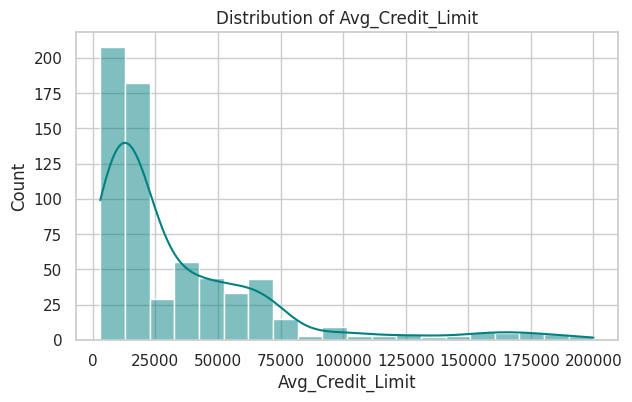

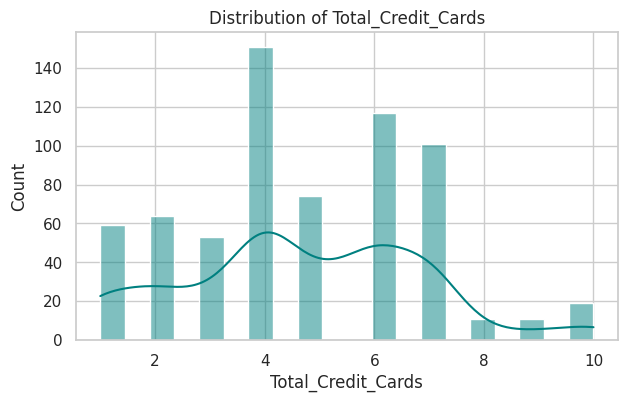

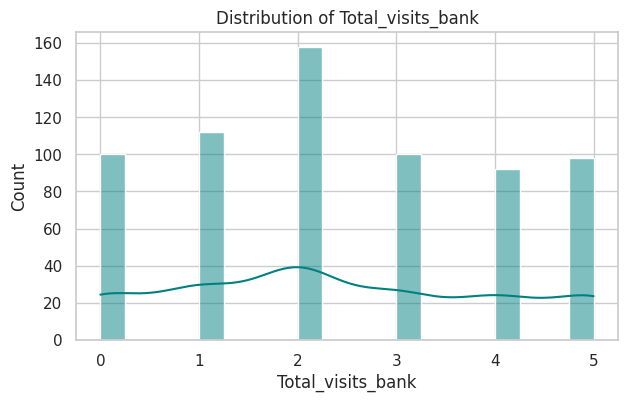

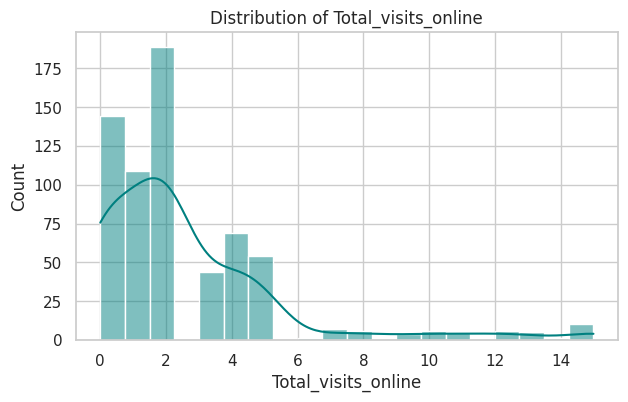

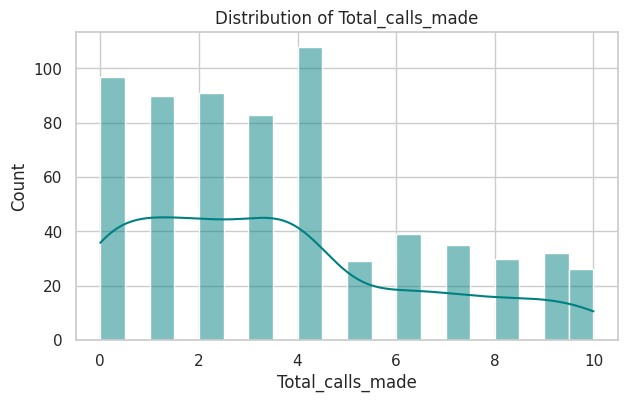

In [189]:
for col in num_cols:

    plt.figure(figsize=(7,4))

    sns.histplot(df[col],
                 kde=True,
                 bins=20,
                 color='teal')

    plt.title(f'Distribution of {col}')

    plt.show()

**Insights**
* Shows skewness
* Detects outliers
* Understands spread
* Identifies customer concentration

### Boxplots

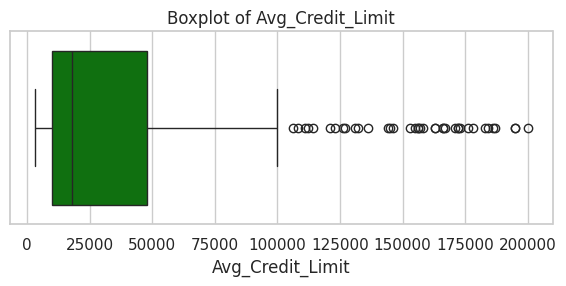

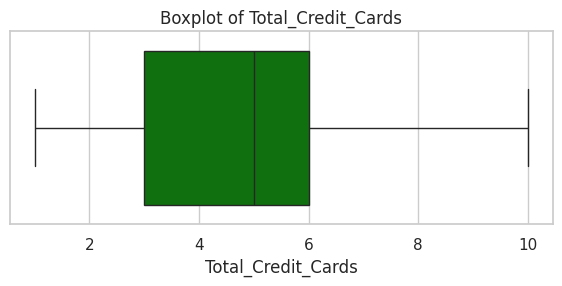

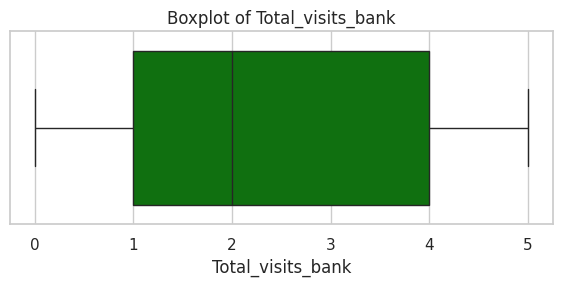

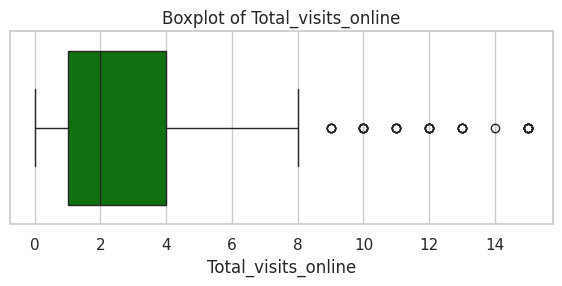

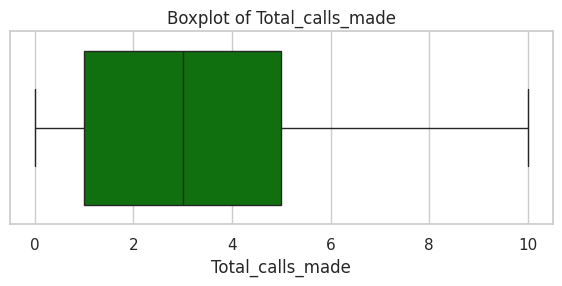

In [190]:
for col in num_cols:

    plt.figure(figsize=(7,2.5))

    sns.boxplot(x=df[col],
                color='green')

    plt.title(f'Boxplot of {col}')

    plt.show()

**Insights**
* Detects outliers
* Shows median
* Shows interquartile range

### Count Plot

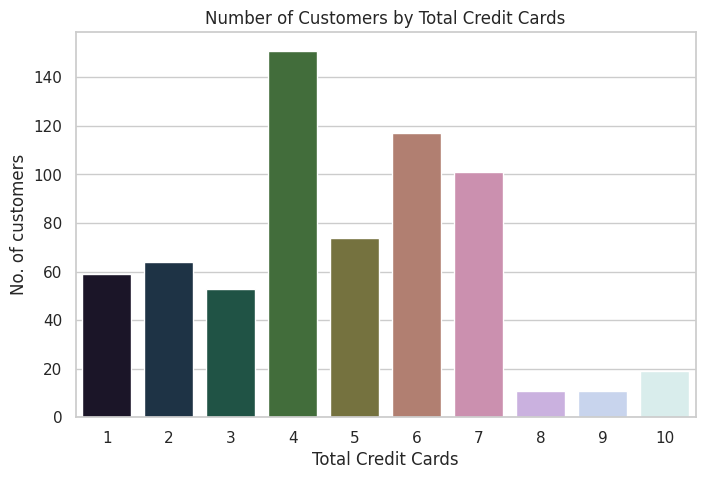

In [191]:
plt.figure(figsize=(8,5))

sns.countplot(x='Total_Credit_Cards',
              data=df,
              palette='cubehelix')

plt.title("Number of Customers by Total Credit Cards")
plt.ylabel("No. of customers")
plt.xlabel("Total Credit Cards")
plt.show()

## Bivariate Analysis

### Pairplot

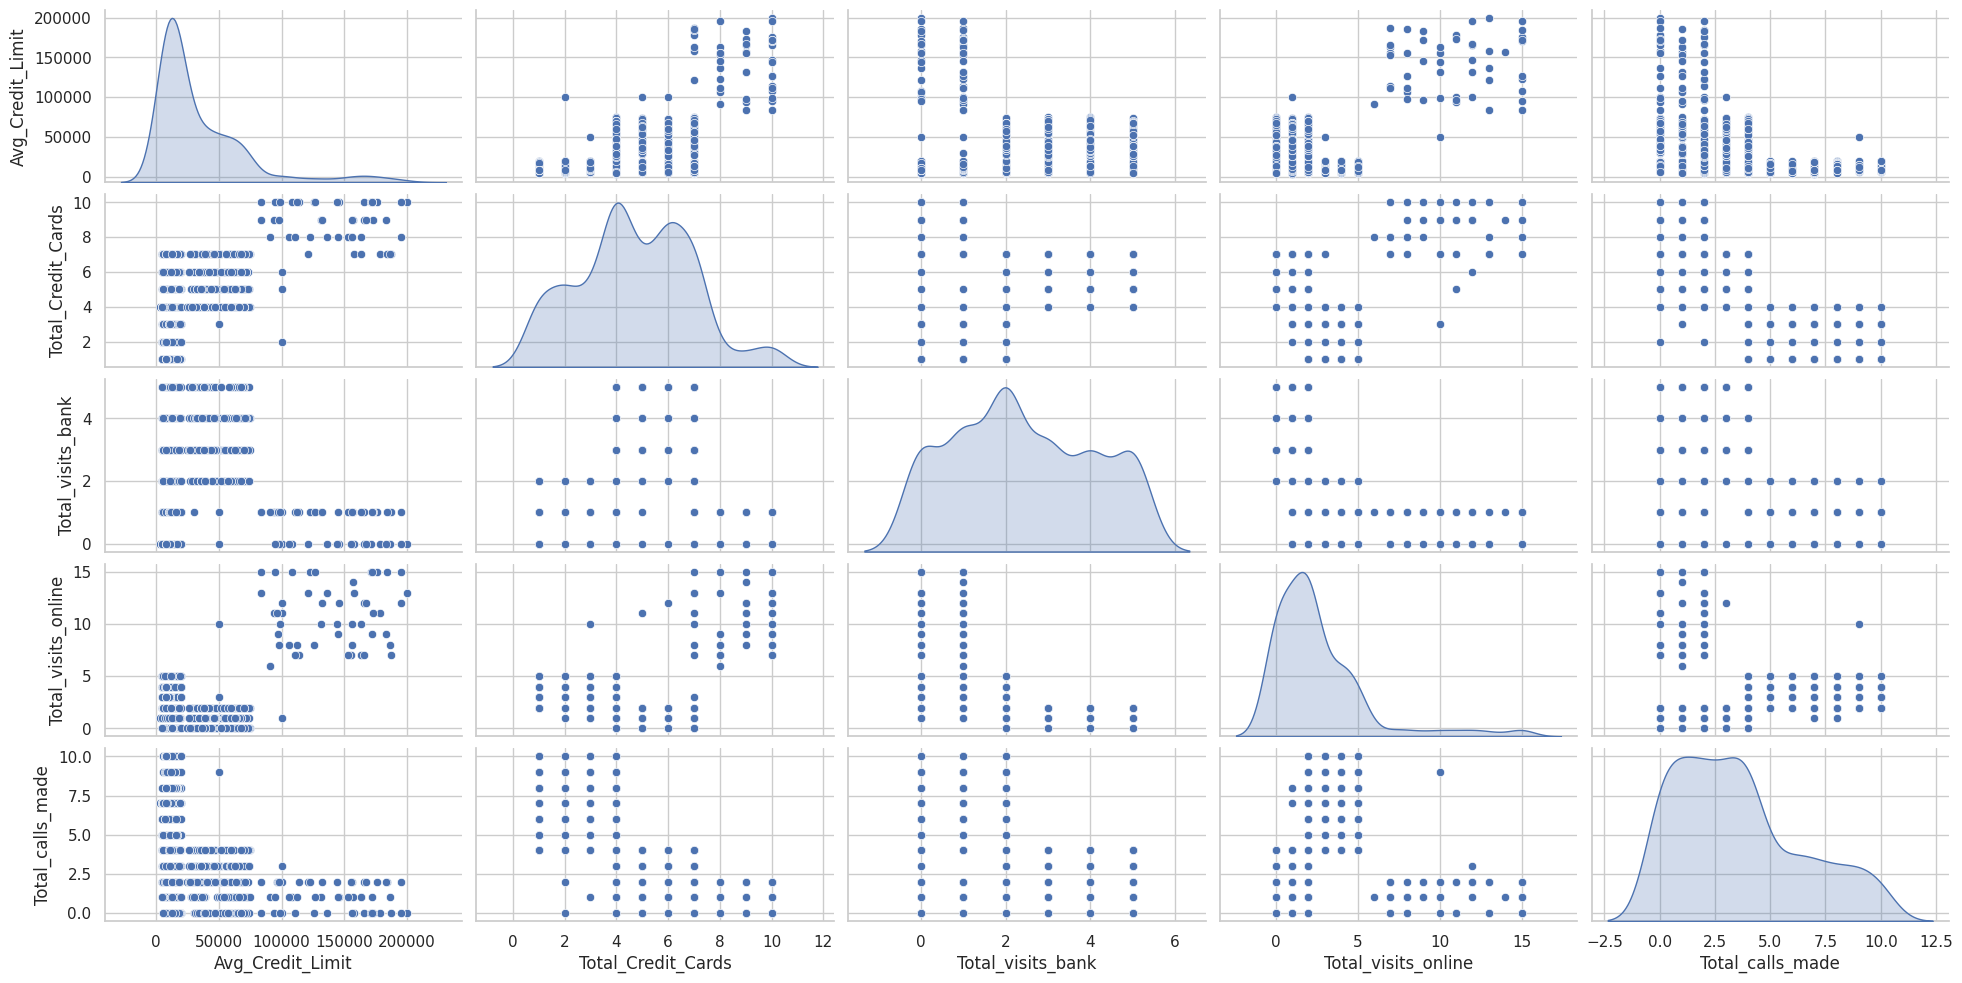

In [192]:
sns.pairplot(df, height=2, aspect=2, diag_kind='kde', palette='rocket_r')

plt.show()

### Credit Limit vs Credit Cards

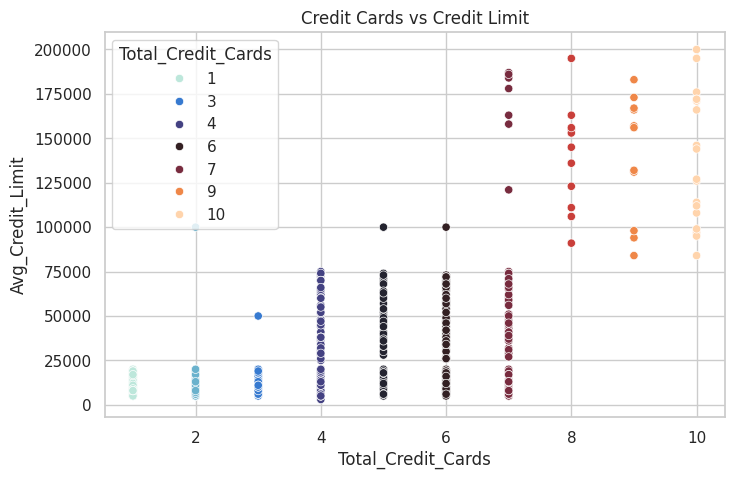

In [193]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df,
                x='Total_Credit_Cards',
                y='Avg_Credit_Limit',
                hue='Total_Credit_Cards',
                palette='icefire')

plt.title("Credit Cards vs Credit Limit")

plt.show()

**Insight**

Higher credit card ownership often corresponds to higher credit limits.

### Online Visits vs Bank Visits

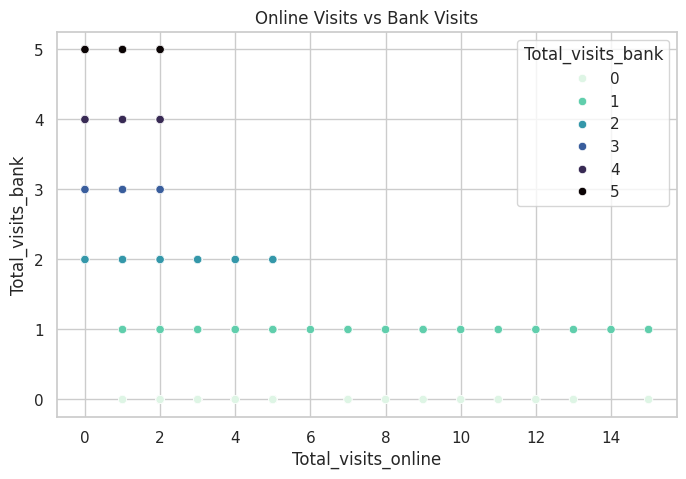

In [194]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df,
                x='Total_visits_online',
                y='Total_visits_bank',
                hue='Total_visits_bank',
                palette='mako_r')
plt.title("Online Visits vs Bank Visits")

plt.show()

**Insight**

Digital customers generally visit banks less frequently.

### Calls vs Credit Limit

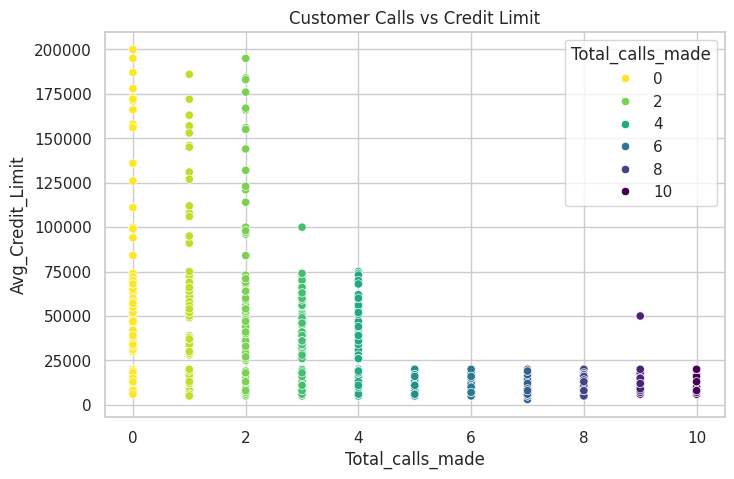

In [195]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df,
                x='Total_calls_made',
                y='Avg_Credit_Limit',
                hue='Total_calls_made',
                palette='viridis_r')

plt.title("Customer Calls vs Credit Limit")

plt.show()

### Credit Limit by Number of Cards

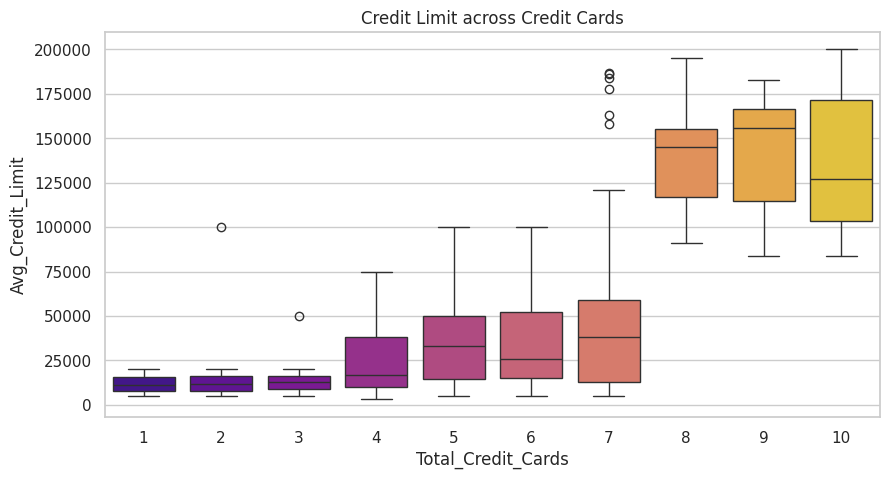

In [196]:
plt.figure(figsize=(10,5))

sns.boxplot(x='Total_Credit_Cards',
            y='Avg_Credit_Limit',
            data=df,
            palette='plasma')

plt.title("Credit Limit across Credit Cards")

plt.show()

### Calls vs Online Visits

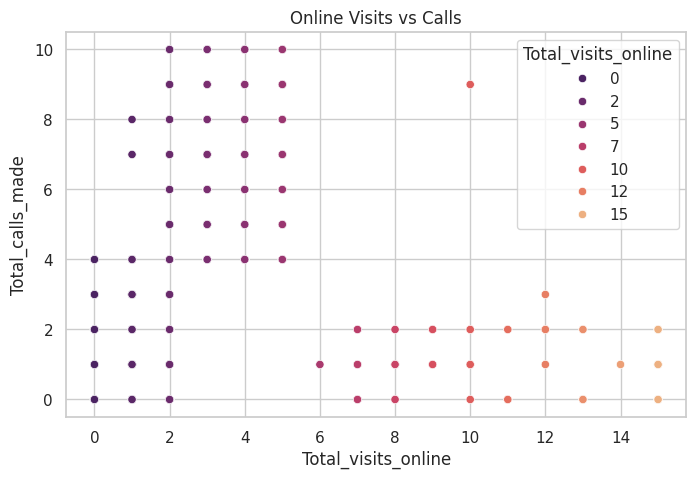

In [197]:
plt.figure(figsize=(8,5))

sns.scatterplot(x='Total_visits_online',
                y='Total_calls_made',
                data=df,
                hue='Total_visits_online',
                palette='flare_r')

plt.title("Online Visits vs Calls")

plt.show()

### Calls vs Bank Visits

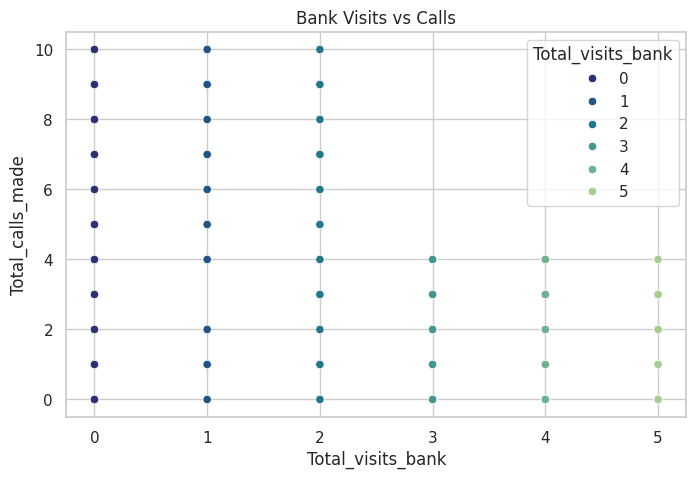

In [198]:
plt.figure(figsize=(8,5))

sns.scatterplot(x='Total_visits_bank',
                y='Total_calls_made',
                data=df,
                hue='Total_visits_bank',
                palette='crest_r')

plt.title("Bank Visits vs Calls")

plt.show()

### Correlation Matrix

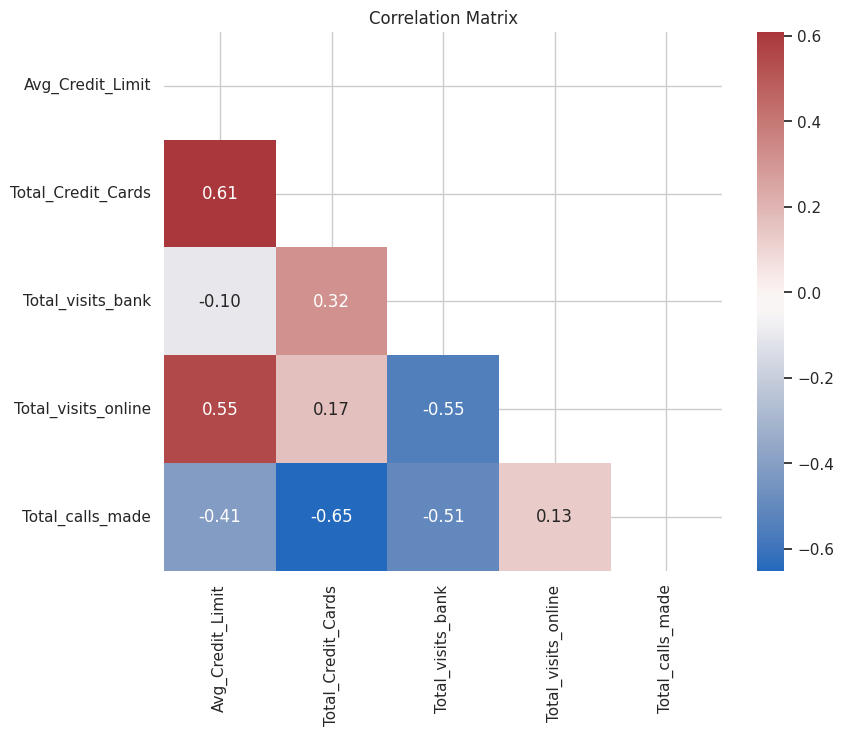

In [199]:
corr=df.corr()

mask=np.triu(np.ones_like(corr,dtype=bool))

plt.figure(figsize=(9,7))

sns.heatmap(corr,
            annot=True,
            cmap="vlag",
            fmt=".2f",
            mask=mask)

plt.title("Correlation Matrix")

plt.show()

### Outlier Detection

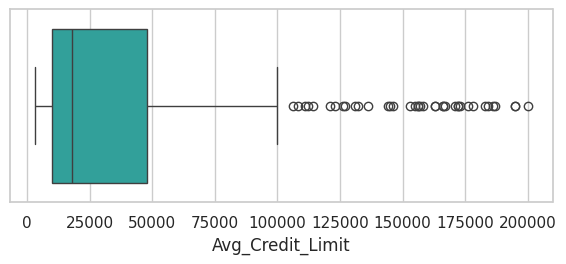

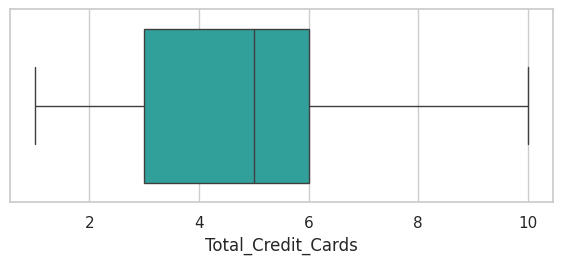

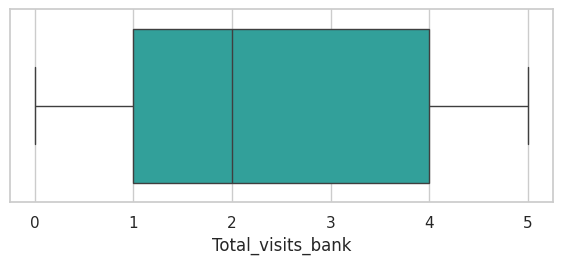

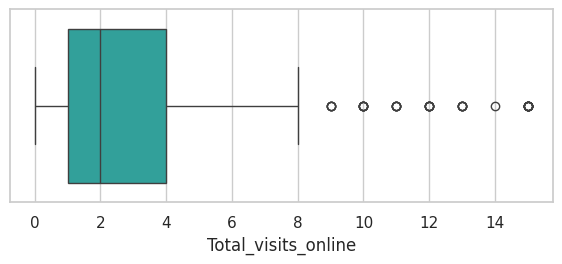

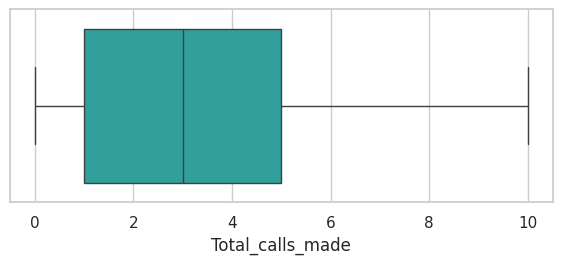

In [200]:
for col in df.columns:

    plt.figure(figsize=(7,2.5))

    sns.boxplot(x=df[col],
                color='lightseagreen')

    plt.show()

## Key meaningful observations

**Avg Credit Limit**
* Right-skewed distribution.
* Few customers have exceptionally high credit limits.
* Indicates the presence of premium customers.

**Total Credit Cards**
* Most customers own only a few credit cards.
* A smaller segment owns multiple cards, suggesting cross-selling potential.

**Bank Visits**
* Majority of customers visit bank branches infrequently.
* A subset relies heavily on branch services.

**Online Visits**
* Many customers actively use online banking.
* Digital engagement varies significantly across customers.

**Customer Service Calls**
* Most customers make relatively few service calls.
* Customers with frequent calls may indicate dissatisfaction or require additional support.

**Correlation Insights**
* Average Credit Limit tends to increase with the number of credit cards, indicating higher-value customers often maintain multiple cards.
* Online Visits and Bank Visits generally exhibit an inverse relationship, suggesting that digitally engaged customers depend less on physical branches.
* Customer Service Calls may show weak relationships with other variables, indicating service interactions are driven by individual needs rather than spending behavior.

## Overall EDA Conclusion

The EDA suggests substantial variation in customer financial behavior and service preferences. Differences in credit limits, card ownership, digital usage, and support interactions indicate that the customer base is heterogeneous. These patterns support the use of clustering algorithms (such as K-Means and Hierarchical Clustering) to identify meaningful customer segments for targeted marketing campaigns and tailored service strategies.

# **Data Preprocessing**

## Missing Value Treatment

In [201]:
# Check Missing Values
df.isnull().sum().sort_values(ascending=False)

,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


## Duplicate Records

In [202]:
print("Duplicate Rows :", df.duplicated().sum())

Duplicate Rows : 11


## Outlier Detection and Treatment

### Outlier Detection

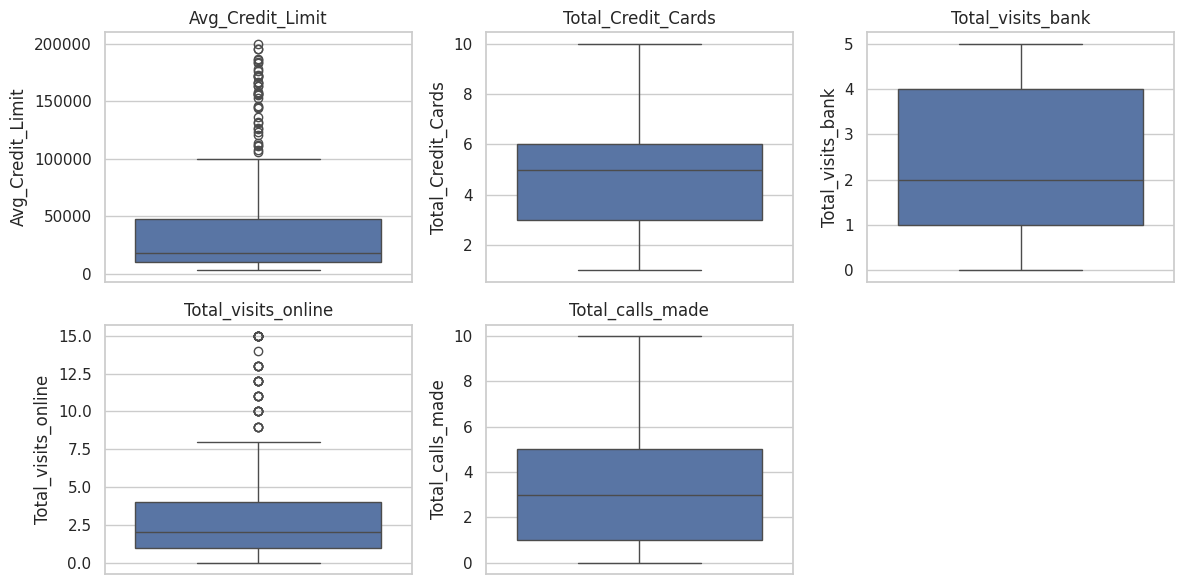

In [203]:
# Boxplots

plt.figure(figsize=(12,6))

for i,col in enumerate(df.columns):

    plt.subplot(2,3,i+1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()


plt.show()

In [204]:
# IQR Method

for col in df.columns:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR

    upper = Q3 + 1.5*IQR

    outliers = df[(df[col]<lower)|(df[col]>upper)]

    print(col,":",len(outliers))

Avg_Credit_Limit : 39
Total_Credit_Cards : 0
Total_visits_bank : 0
Total_visits_online : 37
Total_calls_made : 0


### Outlier Treatment

In [205]:
for col in df.columns:

    Q1=df[col].quantile(0.25)

    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower=Q1-1.5*IQR

    upper=Q3+1.5*IQR

    df[col]=np.where(df[col]>upper,upper,df[col])

    df[col]=np.where(df[col]<lower,lower,df[col])

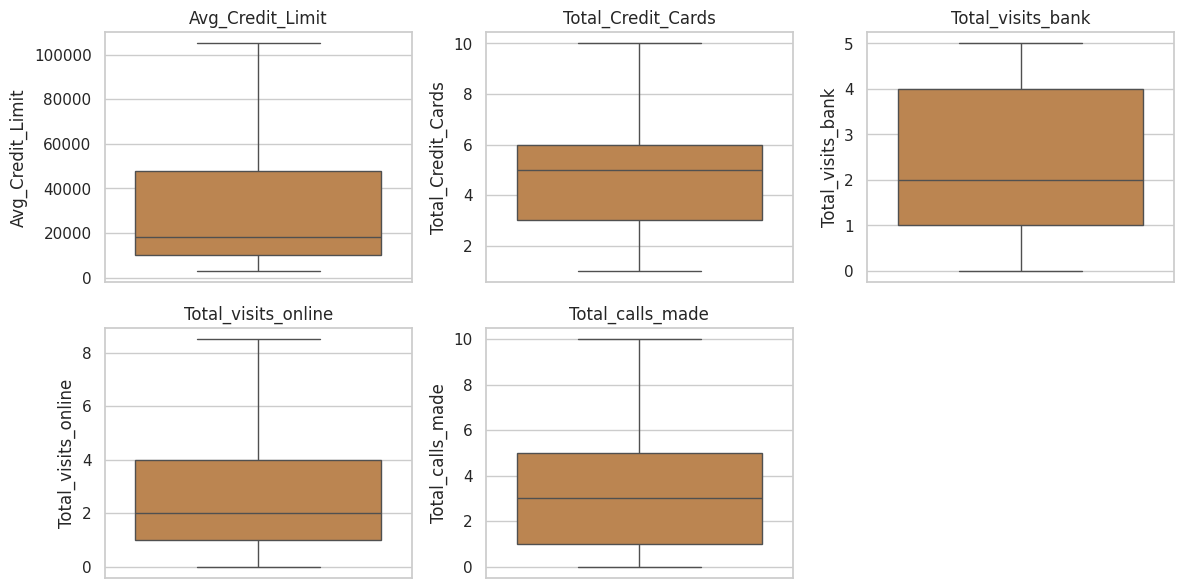

In [206]:
plt.figure(figsize=(12,9))
for i,col in enumerate(df.columns):

    plt.subplot(3,3,i+1)

    sns.boxplot(y=df[col],
                color='peru')

    plt.title(col)

plt.tight_layout()

plt.show()

## Feature Engineering

In [207]:
df["Customer_Engagement"] = (
    df["Total_visits_bank"] +
    df["Total_visits_online"] +
    df["Total_calls_made"]
)

In [208]:
df["Digital_Ratio"] = (
    df["Total_visits_online"] /
    (df["Total_visits_bank"] + 1)
)

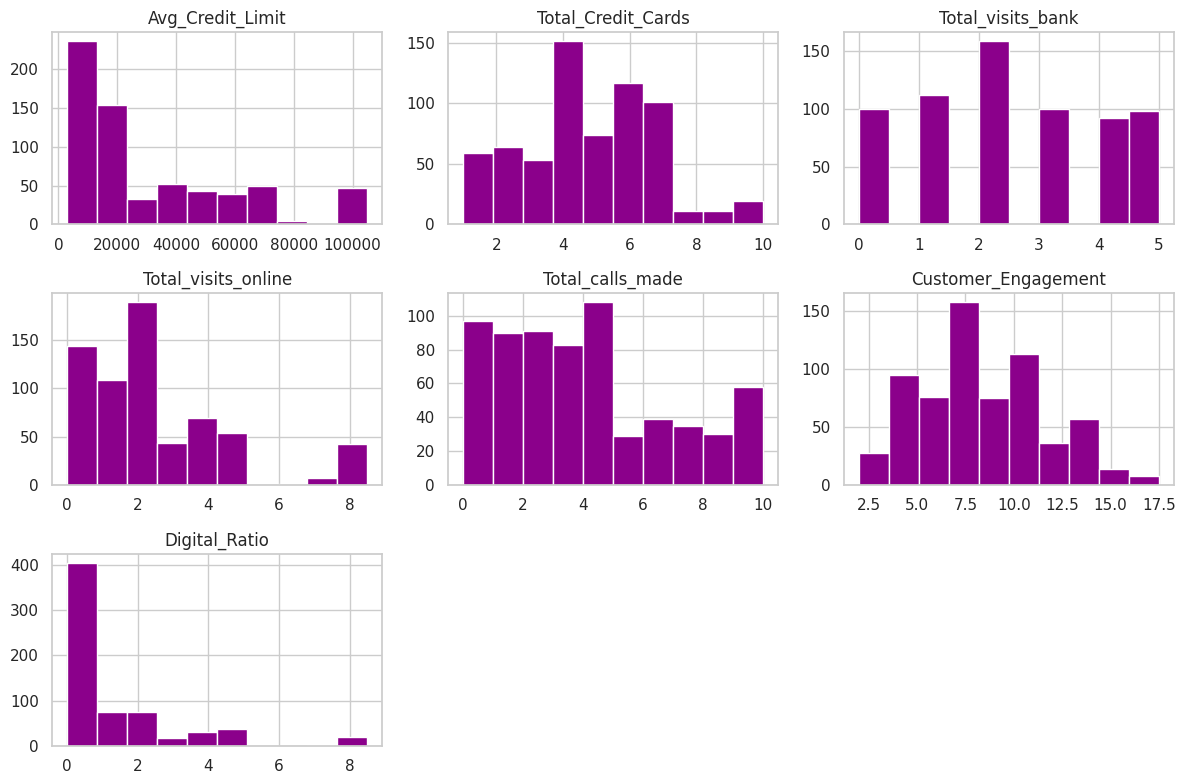

In [209]:
# Check Feature Distribution

df.hist(figsize=(12,8), color='darkmagenta')

plt.tight_layout()

plt.show()

**Rationale**

* Customer_Engagement summarizes overall interaction with the bank.
* Digital_Ratio distinguishes digital-first customers from branch-dependent customers.
* These engineered features can enhance cluster interpretability but are optional.

## Data Scaling

Since K-Means uses Euclidean distance, variables with larger magnitudes dominate the clustering process.

For example:

* Avg Credit Limit ranges from thousands to hundreds of thousands.
* Visits range from 0–15.

Without scaling, Credit Limit would dominate all other variables.

In [210]:
# Standardization

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=df.columns
)

scaled_df.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio
0,2.398942,-1.249225,-0.860451,-0.619767,-1.251537,-2.032908,-0.449550
1,0.643619,-0.787585,-1.473731,2.705813,1.891859,2.902811,3.905986
2,0.643619,1.058973,-0.860451,0.267054,0.145528,-0.122307,0.094892
3,-0.058511,0.135694,-0.860451,-0.619767,0.145528,-0.759174,-0.449550
4,2.398942,0.597334,-1.473731,2.705813,-0.203739,0.992210,3.905986


In [211]:
scaled_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Avg_Credit_Limit,660.0,4.306320e-17,1.000758,-1.006385,-0.760640,-0.479788,0.573406,2.574474
Total_Credit_Cards,660.0,4.306320e-17,1.000758,-1.710864,-0.787585,0.135694,0.597334,2.443892
Total_visits_bank,660.0,-4.306320e-17,1.000758,-1.473731,-0.860451,-0.247170,0.979390,1.592670
Total_visits_online,660.0,-9.689219e-17,1.000758,-1.063178,-0.619767,-0.176357,0.710465,2.705813
Total_calls_made,660.0,-8.612639e-17,1.000758,-1.251537,-0.902271,-0.203739,0.494794,2.241125
Customer_Engagement,660.0,-2.153160e-16,1.000758,-2.032908,-0.759174,-0.122307,0.514560,2.902811
Digital_Ratio,660.0,4.306320e-17,1.000758,-0.721771,-0.617419,-0.449550,0.367113,3.905986


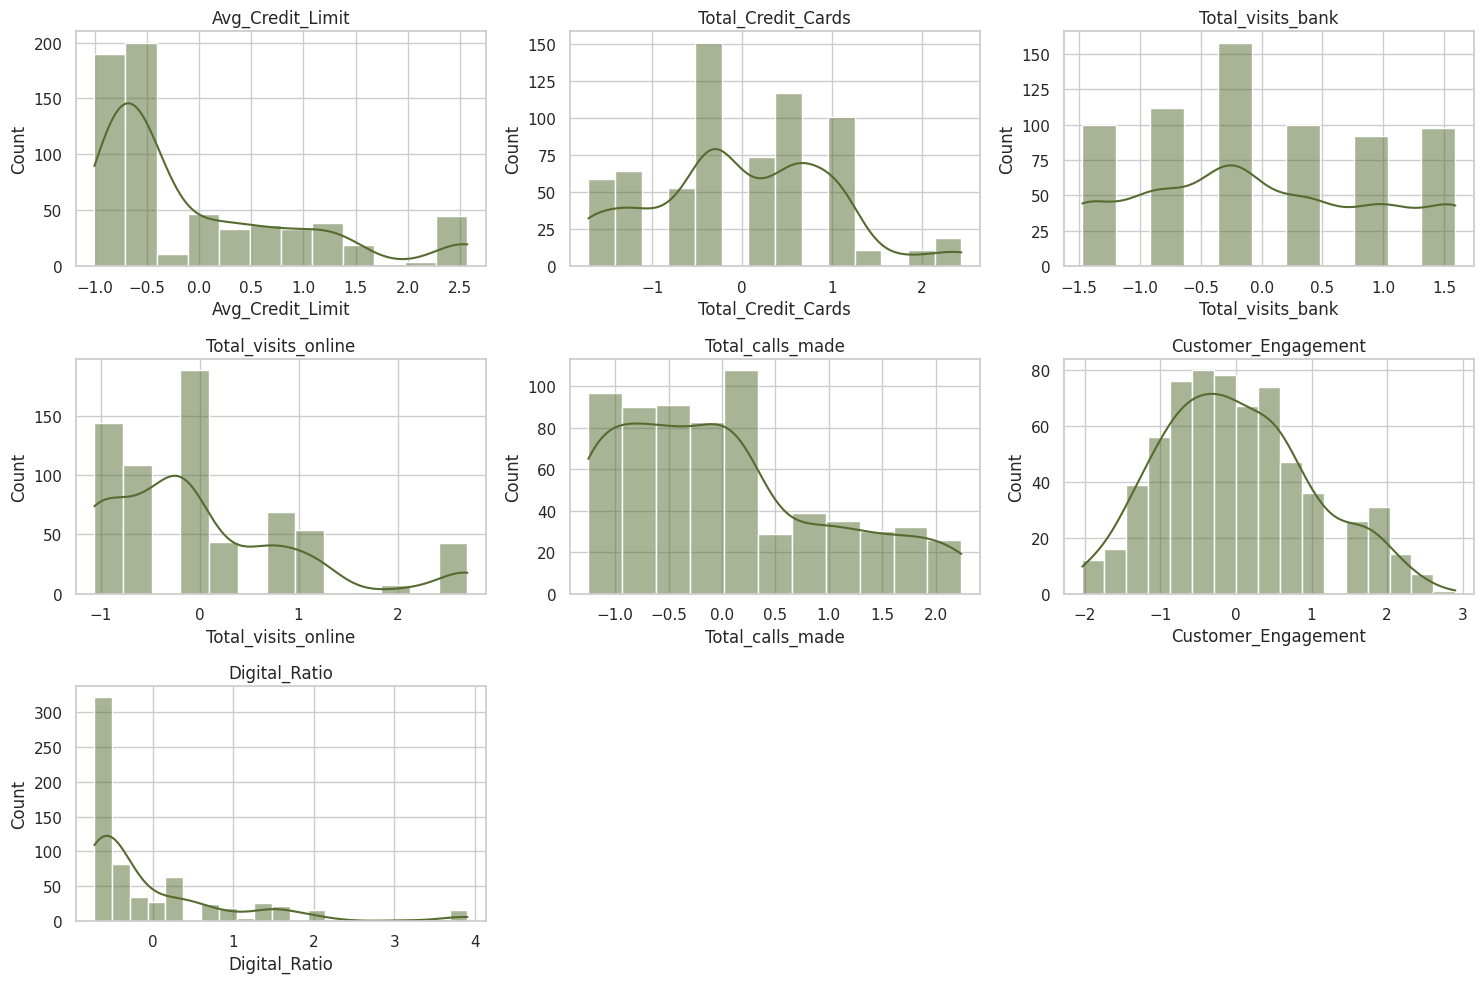

In [212]:
# Distribution After Scaling

plt.figure(figsize=(15,10))

for i,col in enumerate(scaled_df.columns):

    plt.subplot(3,3,i+1)

    sns.histplot(scaled_df[col], kde=True, color='darkolivegreen')

    plt.title(col)

plt.tight_layout()

plt.show()

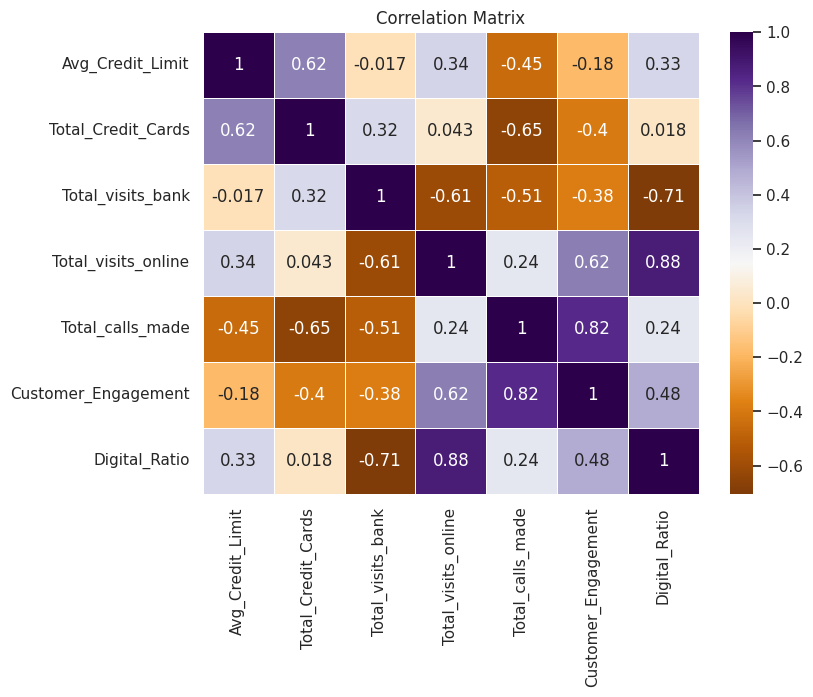

In [213]:
# Correlation After Scaling

plt.figure(figsize=(8,6))

sns.heatmap(
    scaled_df.corr(),
    annot=True,
    cmap="PuOr",
    linewidths=0.5
)

plt.title("Correlation Matrix")

plt.show()

In [214]:
# Final Dataset Ready for Clustering

scaled_df.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio
0,2.398942,-1.249225,-0.860451,-0.619767,-1.251537,-2.032908,-0.449550
1,0.643619,-0.787585,-1.473731,2.705813,1.891859,2.902811,3.905986
2,0.643619,1.058973,-0.860451,0.267054,0.145528,-0.122307,0.094892
3,-0.058511,0.135694,-0.860451,-0.619767,0.145528,-0.759174,-0.449550
4,2.398942,0.597334,-1.473731,2.705813,-0.203739,0.992210,3.905986


## Key Observations

**Missing Values**
* No missing values were found in the dataset (or they were handled using median imputation).
* The dataset is complete and suitable for clustering.

**Duplicate Records**
* Duplicate customer records were removed (if any) to prevent biased cluster formation.

**Identifier Variables**
* Sl_No and Customer Key were removed because they uniquely identify customers but do not reflect customer behavior.

**Outlier Detection**
* Outliers were identified using the IQR method.
* Extreme values mainly occurred in Avg_Credit_Limit, representing premium customers.
* Winsorization (capping) was applied instead of deletion to preserve valuable customer information while limiting undue influence on distance calculations.

**Feature Engineering**
* Optional behavioral features such as Customer_Engagement and Digital_Ratio were created to capture overall interaction and digital preference.
* These features can improve cluster interpretability if included.

**Data Scaling**
* Standardization (StandardScaler) was applied to ensure all features contribute equally to the Euclidean distance used by clustering algorithms.
* This prevents variables with larger numerical ranges (such as Avg_Credit_Limit) from dominating the clustering process.

# **K-means Clustering**

## Elbow Method

In [215]:
inertia = []

K = range(2,11)

for k in K:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(scaled_df)

    inertia.append(model.inertia_)

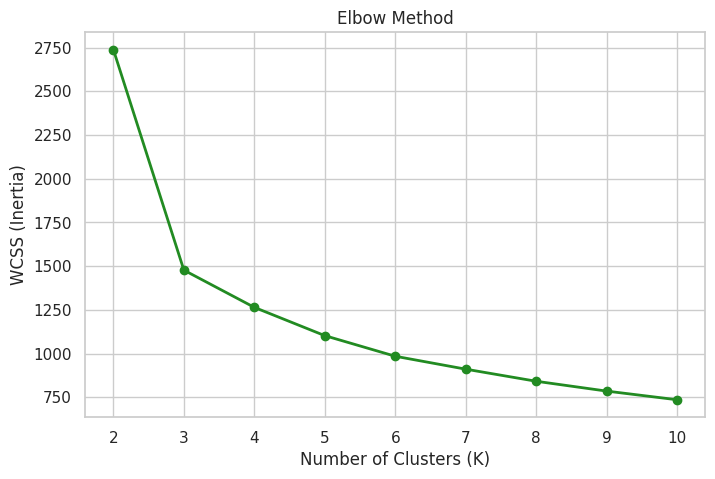

In [216]:
plt.figure(figsize=(8,5))

plt.plot(
    K,
    inertia,
    marker='o',
    linewidth=2,
    color='forestgreen'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")

plt.grid(True)

plt.show()

## Silhouette Scores

In [217]:
silhouette_scores = []

K = range(2,11)

for k in K:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_df)

    score = silhouette_score(
        scaled_df,
        labels
    )

    silhouette_scores.append(score)

In [218]:
for k,score in zip(K,silhouette_scores):

    print(f"K = {k}  -->  Silhouette Score = {score:.3f}")

K = 2  -->  Silhouette Score = 0.431
K = 3  -->  Silhouette Score = 0.508
K = 4  -->  Silhouette Score = 0.337
K = 5  -->  Silhouette Score = 0.270
K = 6  -->  Silhouette Score = 0.269
K = 7  -->  Silhouette Score = 0.269
K = 8  -->  Silhouette Score = 0.265
K = 9  -->  Silhouette Score = 0.249
K = 10  -->  Silhouette Score = 0.249


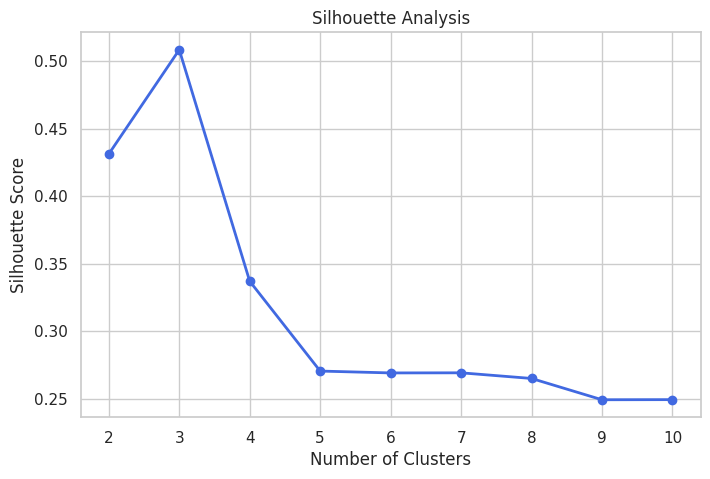

In [219]:
plt.figure(figsize=(8,5))

plt.plot(
    K,
    silhouette_scores,
    marker='o',
    color='royalblue',
    linewidth=2
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Analysis")

plt.grid(True)

plt.show()

*Choosing the Best Number of Clusters*

Generally choose the value of K where:

* The Elbow curve begins to flatten.
* The Silhouette Score is relatively high.

For the AllLife Bank dataset, the optimal number of clusters is commonly found to be 3.

## Train the Final K-Means Model

In [220]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(scaled_df)

In [221]:
# Add Cluster Labels

cluster_df = df.copy()

cluster_df["Cluster"] = clusters

cluster_df.head(10)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio,Cluster
0,100000.0,2.0,1.0,1.0,0.0,2.0,0.5,2
1,50000.0,3.0,0.0,8.5,9.0,17.5,8.5,0
2,50000.0,7.0,1.0,3.0,4.0,8.0,1.5,2
3,30000.0,5.0,1.0,1.0,4.0,6.0,0.5,2
4,100000.0,6.0,0.0,8.5,3.0,11.5,8.5,1
5,20000.0,3.0,0.0,1.0,8.0,9.0,1.0,0
6,100000.0,5.0,0.0,8.5,2.0,10.5,8.5,1
7,15000.0,3.0,0.0,1.0,1.0,2.0,1.0,2
8,5000.0,2.0,0.0,2.0,2.0,4.0,2.0,0
9,3000.0,4.0,0.0,1.0,7.0,8.0,1.0,0


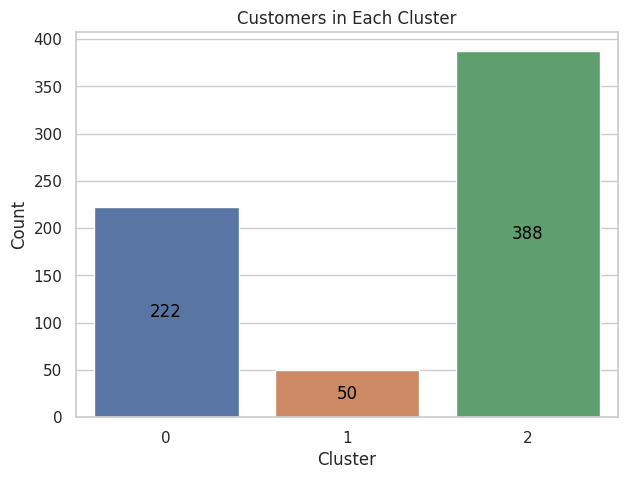

In [222]:
plt.figure(figsize=(7,5))

ax = sns.countplot(
    x="Cluster",
    data=cluster_df,
    palette="deep"
)

plt.title("Customers in Each Cluster")

plt.xlabel("Cluster")

plt.ylabel("Count")

# Add cluster numbers in the middle of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', label_type='center', color='black')

plt.show()

## Cluster Profiling

In [223]:
kmeans_profile = cluster_df.groupby("Cluster").mean()

kmeans_profile

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio
Cluster,,,,,,,
0,12184.684685,2.400901,0.932432,3.565315,6.909910,11.407658,2.234985
1,102660.000000,8.740000,0.600000,8.180000,1.080000,9.860000,5.745000
2,33664.948454,5.505155,3.476804,0.984536,2.002577,6.463918,0.235954


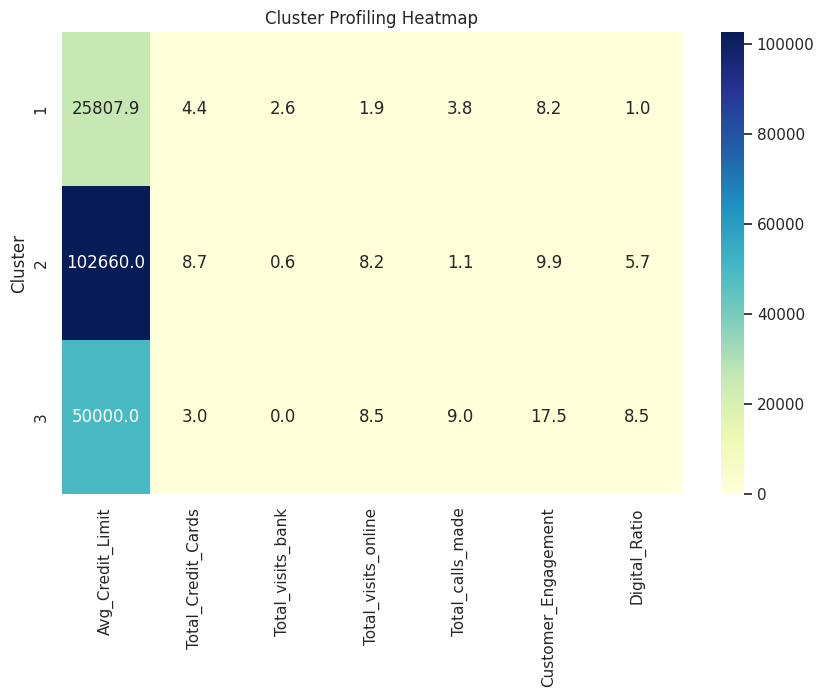

In [224]:
# Heatmap

plt.figure(figsize=(10,6))

sns.heatmap(
    cluster_profile,
    annot=True,
    cmap="YlGnBu",
    fmt=".1f"
)

plt.title("Cluster Profiling Heatmap")

plt.show()

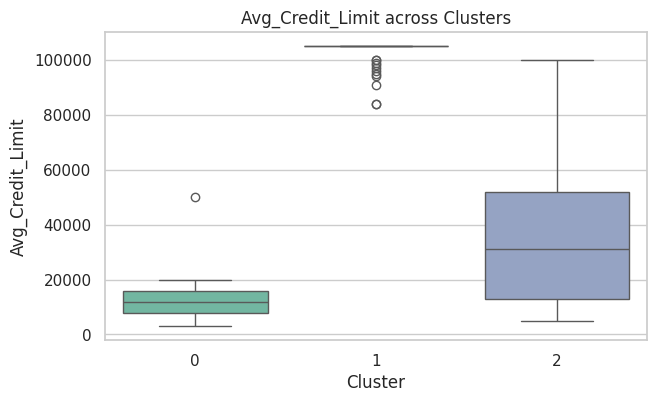

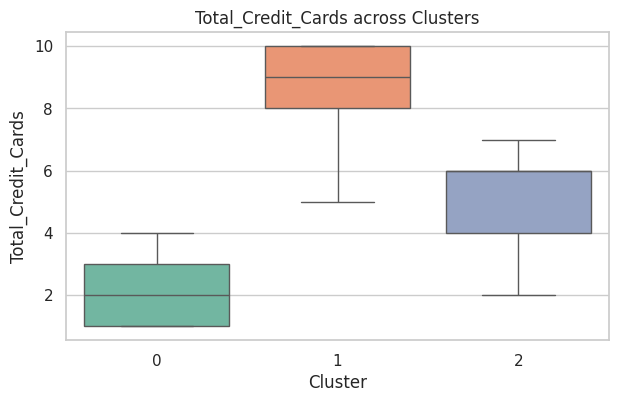

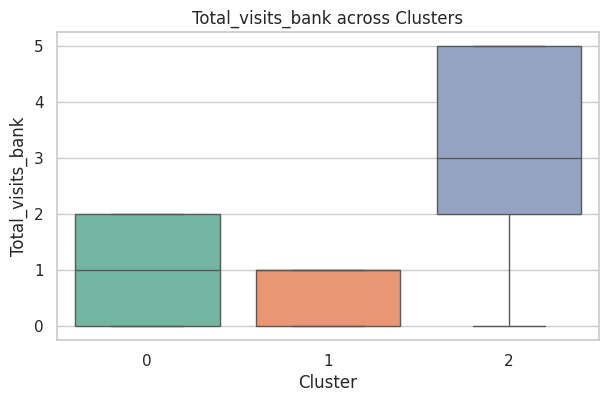

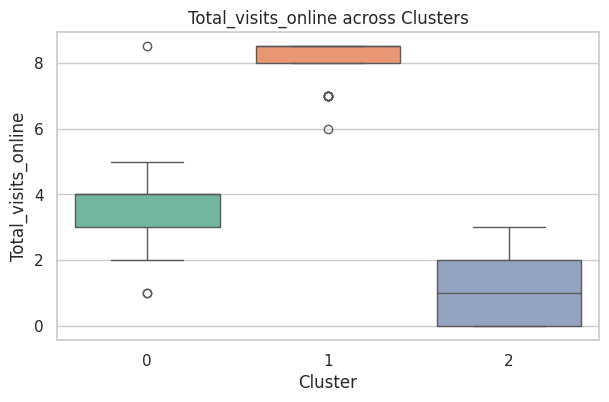

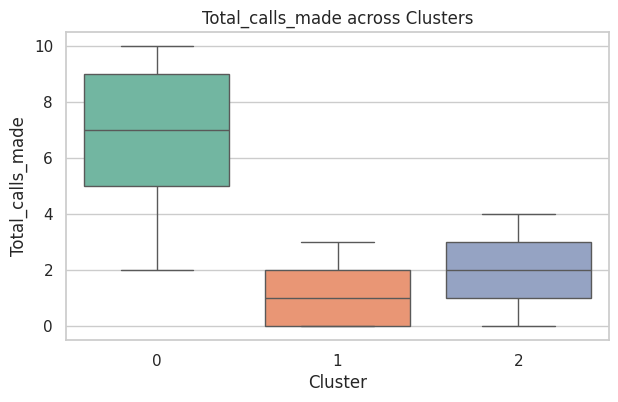

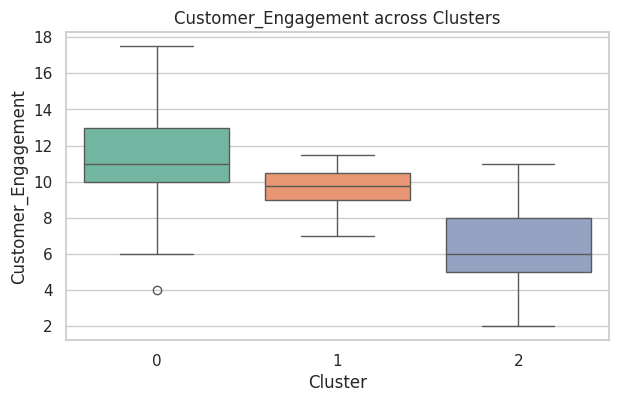

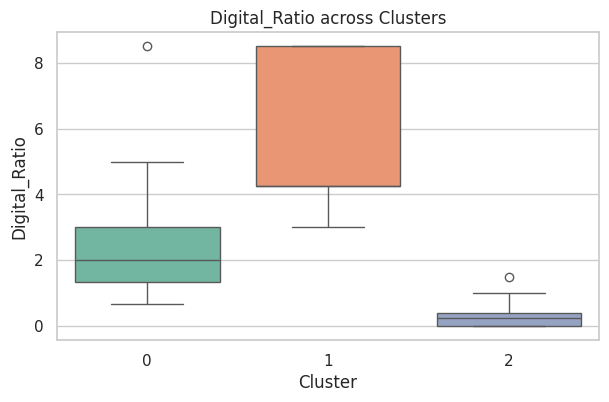

In [225]:
# Boxplots

features = cluster_df.columns[:-1]

for col in features:

    plt.figure(figsize=(7,4))

    sns.boxplot(
        x="Cluster",
        y=col,
        data=cluster_df,
        palette="Set2"
    )

    plt.title(f"{col} across Clusters")

    plt.show()

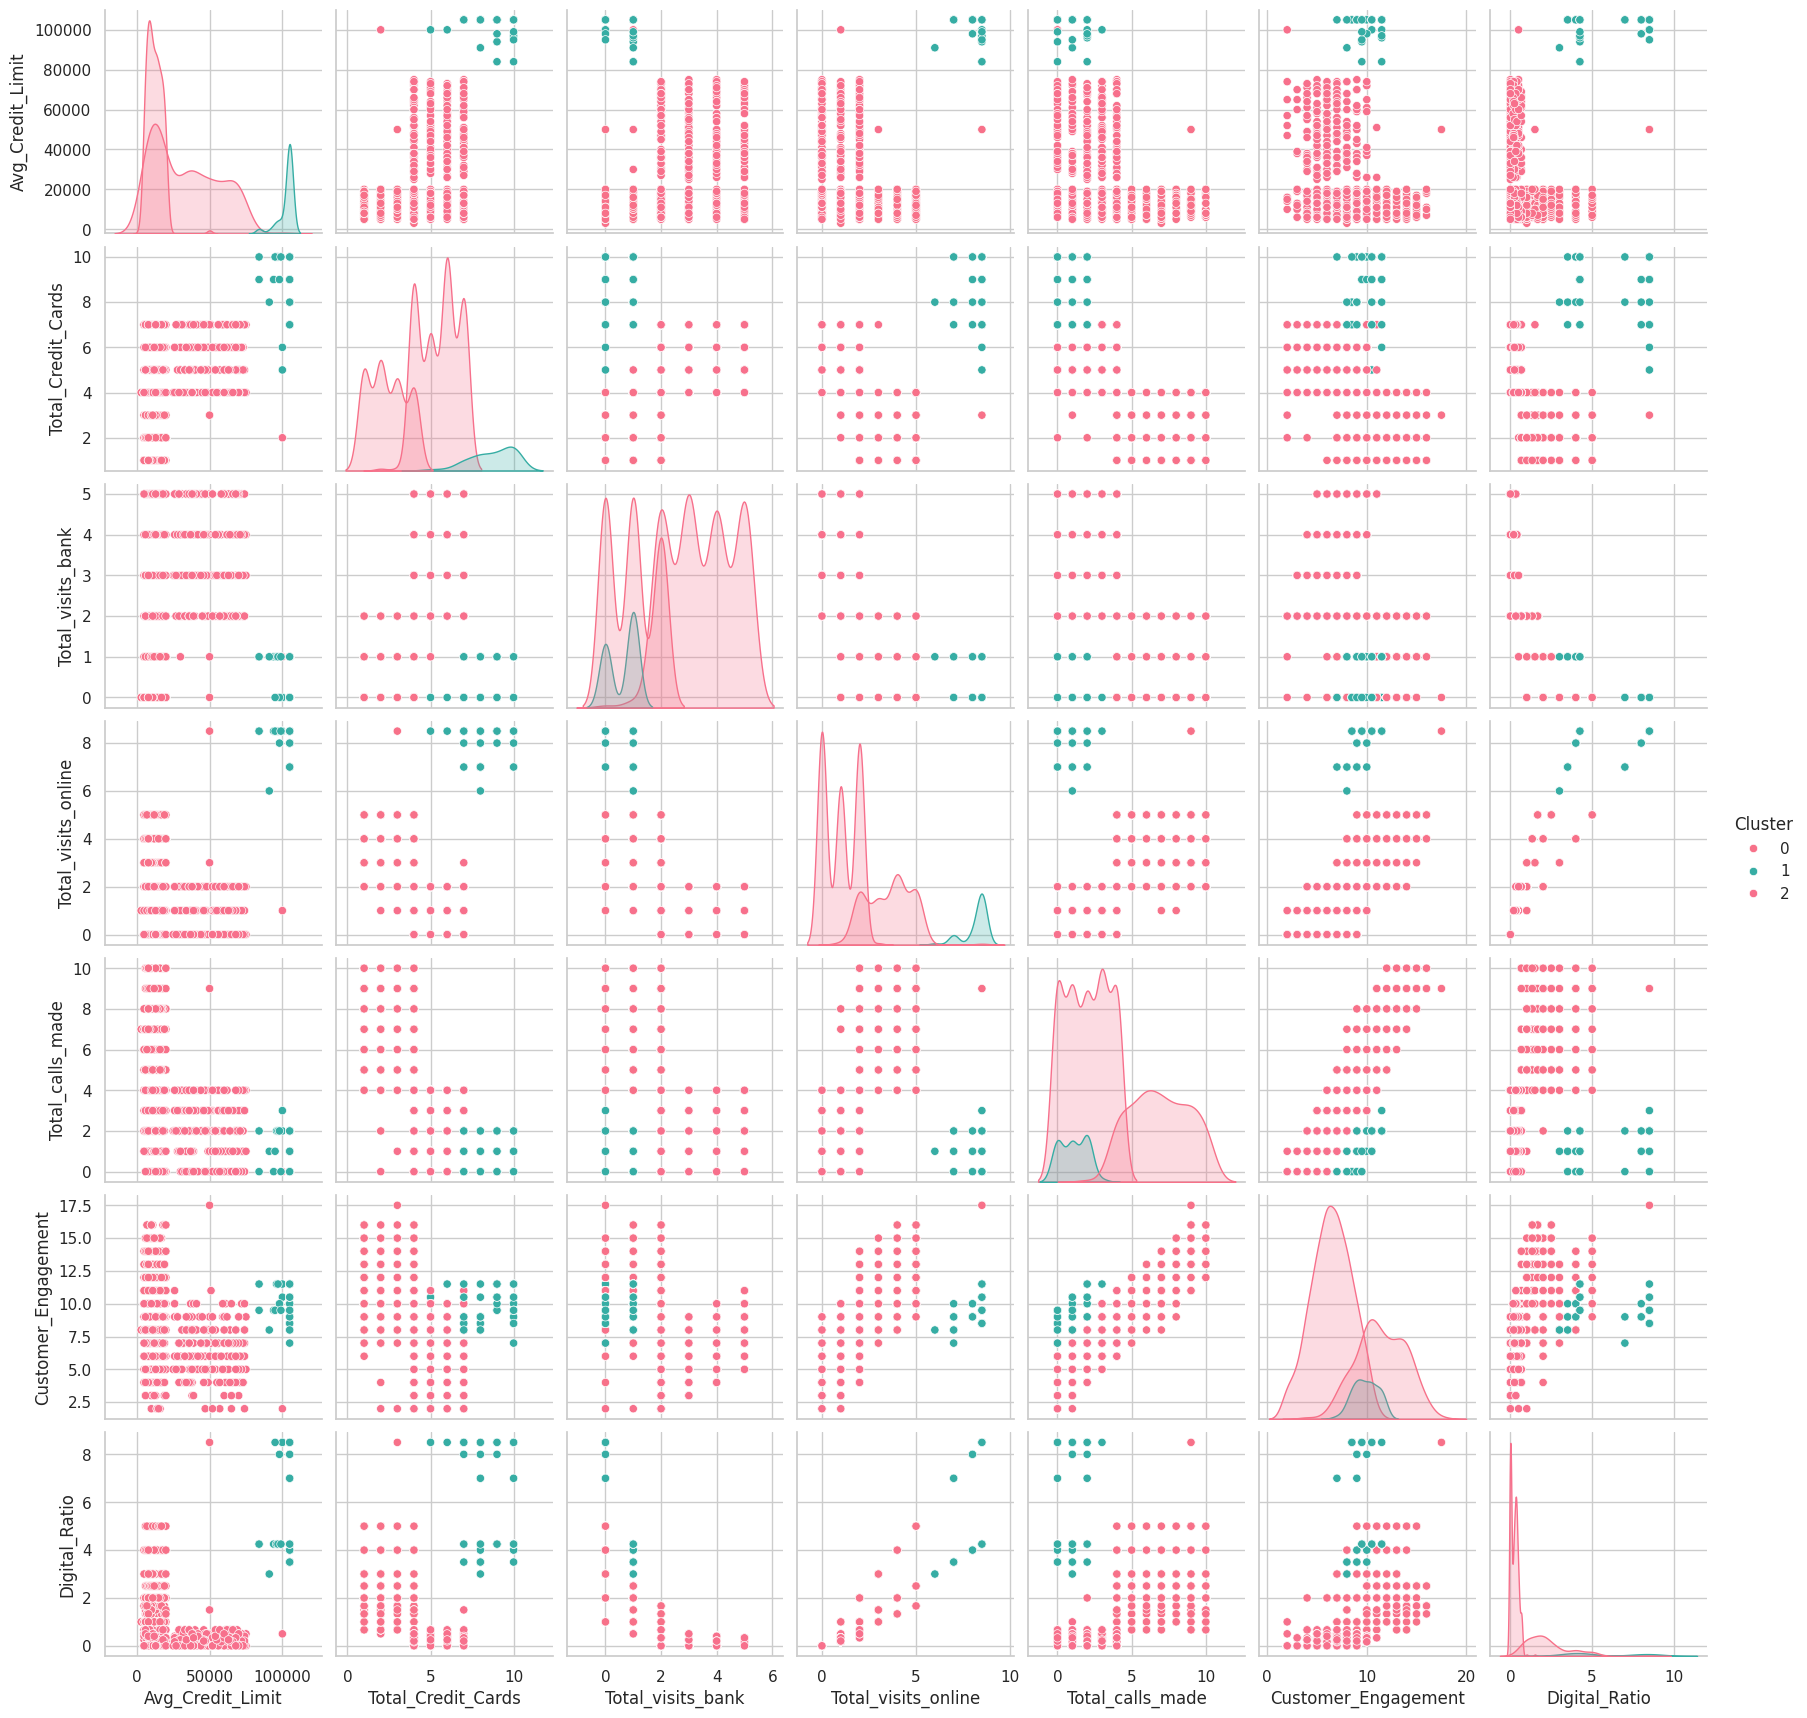

In [226]:
# Pairplot

sns.pairplot(
    cluster_df,
    hue="Cluster",
    palette="husl"
)

plt.show()

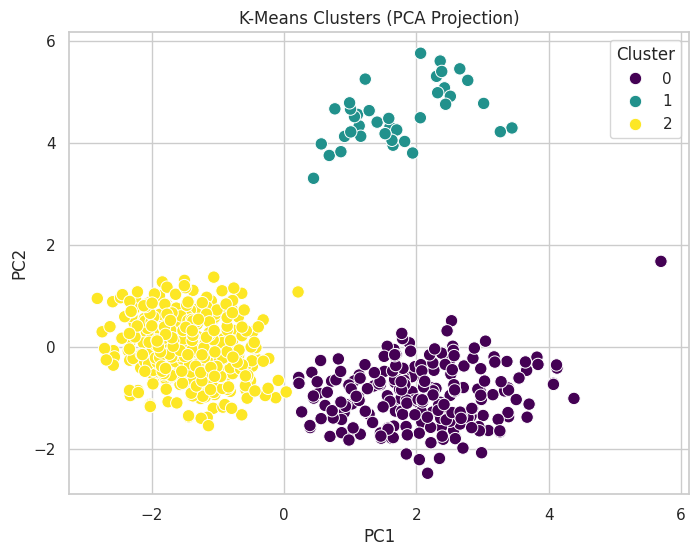

In [227]:
# PCA Visualization

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_df)

plot_df = pd.DataFrame(pca_data, columns=["PC1","PC2"])

plot_df["Cluster"] = clusters

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("K-Means Clusters (PCA Projection)")

plt.show()

In [228]:
# Cluster Centroids

centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=scaled_df.columns
)

centroids

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio
0,-0.683944,-1.064153,-0.901888,0.517721,1.161861,0.962805,0.495049
1,2.492325,1.862226,-1.105763,2.563922,-0.874330,0.469979,2.406049
2,0.070153,0.368893,0.658524,-0.626624,-0.552105,-0.611448,-0.593308


# **Hierarchical Clustering**

##  Linkage Methods

In [229]:
# Distance Matrix
distance_matrix = pdist(scaled_df)

**Apply Different Linkage Methods**

We'll compare four linkage methods:

* Single
* Complete
* Average
* Ward

In [230]:
linkage_methods = ['single','complete','average','ward']

linkage_models = {}

for method in linkage_methods:

    linkage_models[method] = linkage(
        scaled_df,
        method=method
    )

### Single Linkage

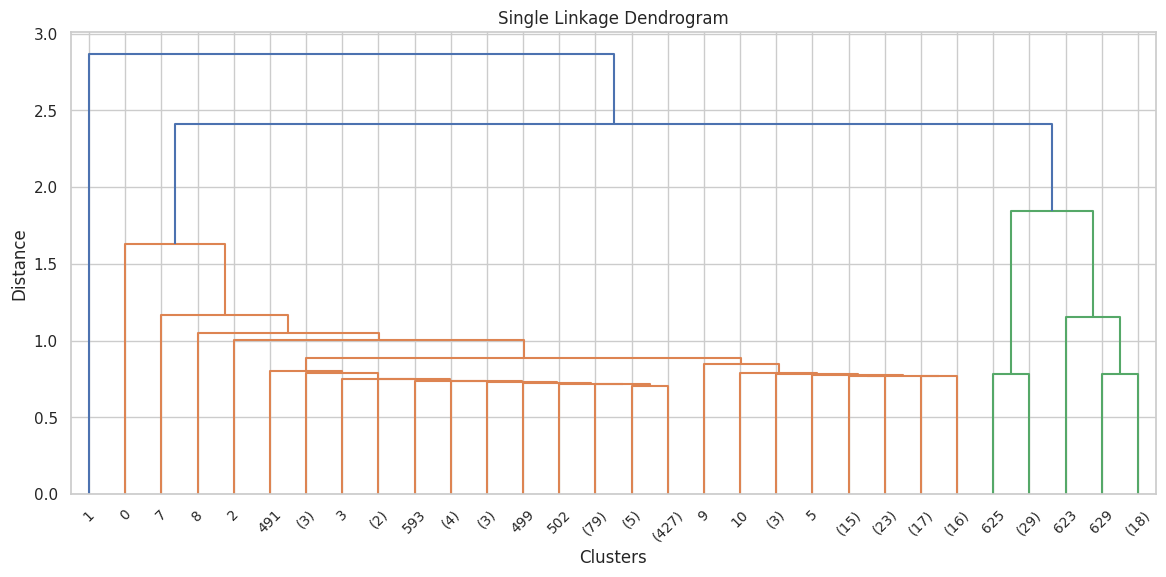

In [231]:
plt.figure(figsize=(14,6))

dendrogram(
    linkage_models['single'],
    truncate_mode='lastp',
    p=30
)

plt.title("Single Linkage Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")

plt.show()

### Complete Linkage

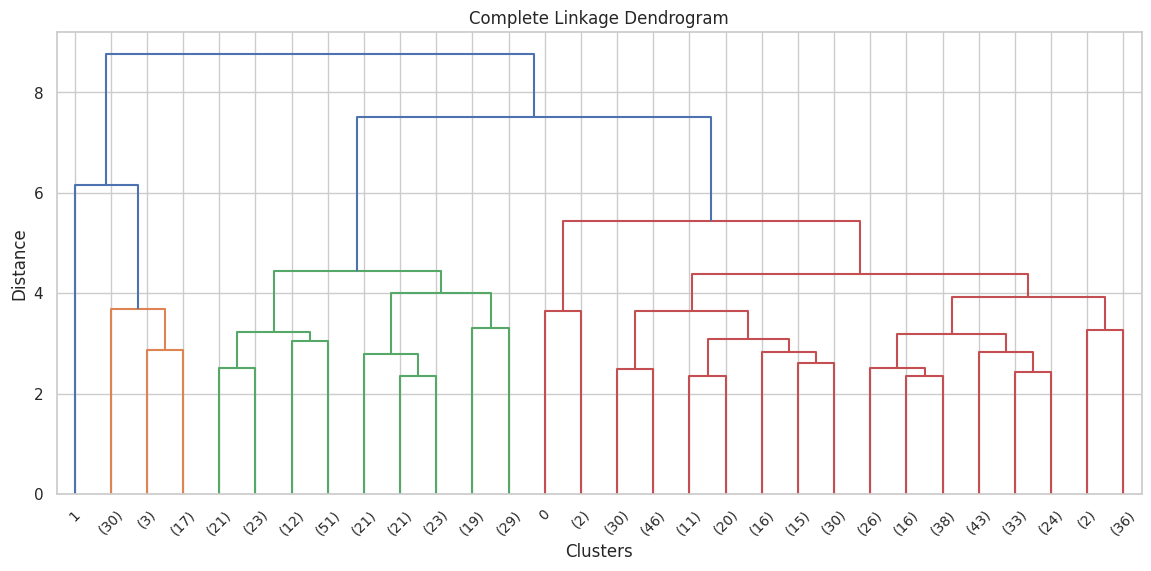

In [232]:
plt.figure(figsize=(14,6))

dendrogram(
    linkage_models['complete'],
    truncate_mode='lastp',
    p=30
)

plt.title("Complete Linkage Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")

plt.show()

### Average Linkage

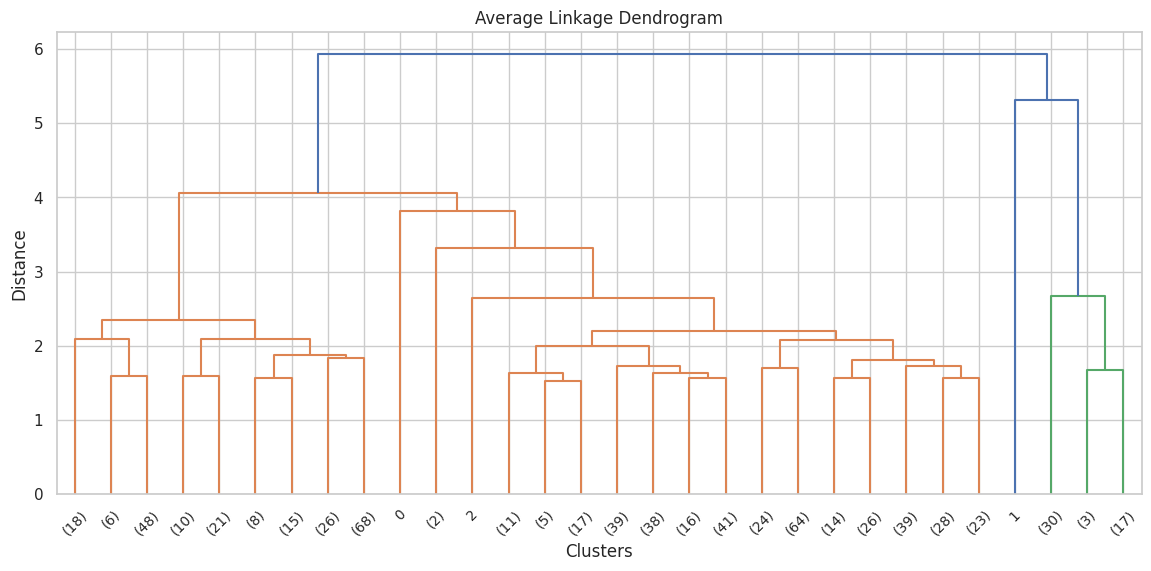

In [233]:
plt.figure(figsize=(14,6))

dendrogram(
    linkage_models['average'],
    truncate_mode='lastp',
    p=30
)

plt.title("Average Linkage Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")

plt.show()

### Ward Linkage

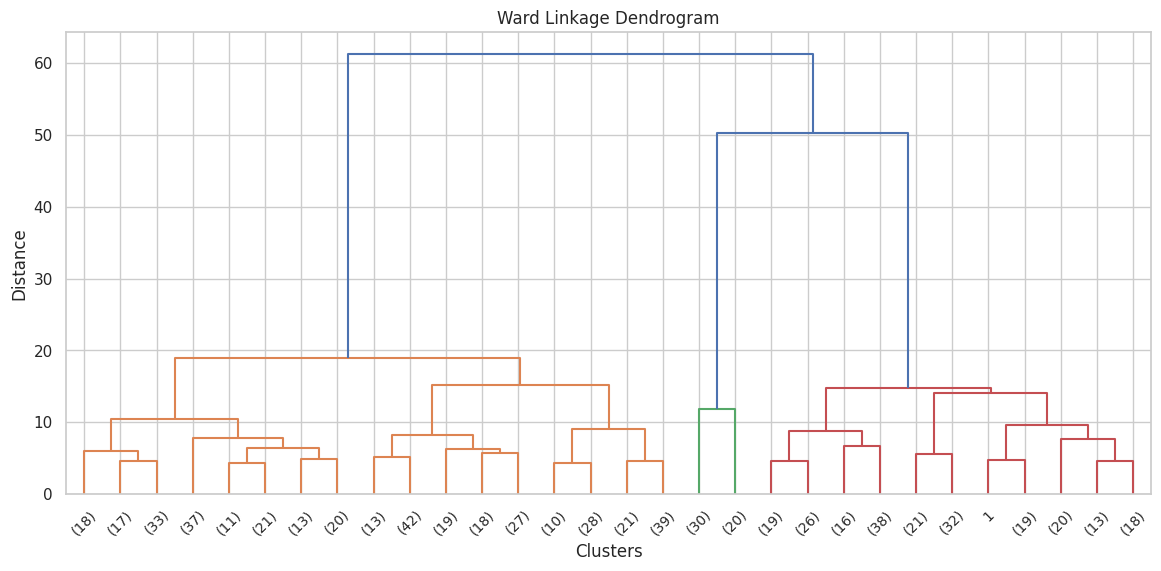

In [234]:
plt.figure(figsize=(14,6))

dendrogram(
    linkage_models['ward'],
    truncate_mode='lastp',
    p=30
)

plt.title("Ward Linkage Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")

plt.show()

## Cophenetic Correlation

In [235]:
for method in linkage_methods:

    coph_corr, coph_dist = cophenet(
        linkage_models[method],
        distance_matrix
    )

    print(method,"=",round(coph_corr,3))

single = 0.682
complete = 0.844
average = 0.88
ward = 0.764


In [236]:
# Select Best Linkage Method

average_linkage = linkage_models['average']

## Number of Clusters

In [237]:
hc_clusters = fcluster(
    average_linkage,
    3,
    criterion='maxclust'
)

In [238]:
# Add Cluster Labels

hc_df = df.copy()

hc_df["Cluster"] = hc_clusters

hc_df.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio,Cluster
0,100000.0,2.0,1.0,1.0,0.0,2.0,0.5,1
1,50000.0,3.0,0.0,8.5,9.0,17.5,8.5,3
2,50000.0,7.0,1.0,3.0,4.0,8.0,1.5,1
3,30000.0,5.0,1.0,1.0,4.0,6.0,0.5,1
4,100000.0,6.0,0.0,8.5,3.0,11.5,8.5,2


In [239]:
# Cluster Size

hc_df.Cluster.value_counts().sort_index()

,count
Cluster,
1,609
2,50
3,1


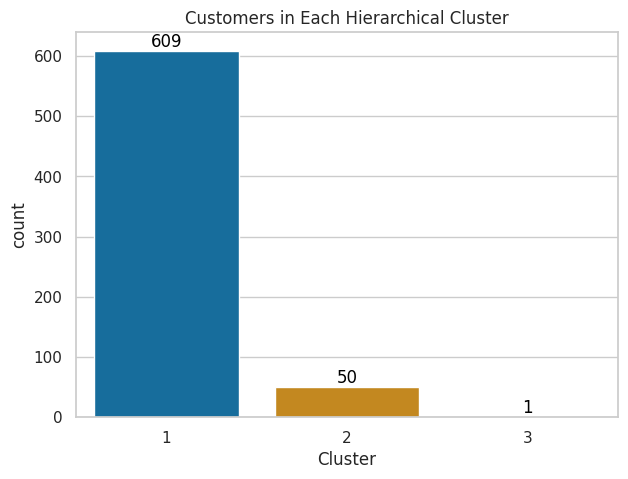

In [240]:
plt.figure(figsize=(7,5))

ax = sns.countplot(
    x="Cluster",
    data=hc_df,
    palette="colorblind"
)

plt.title("Customers in Each Hierarchical Cluster")

# Add count numbers on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', label_type='edge', color='black')

plt.show()

## Cluster Profiling

In [241]:
cluster_profile = hc_df.groupby("Cluster").mean()

cluster_profile

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio
Cluster,,,,,,,
1,25807.881773,4.377668,2.555008,1.912972,3.779967,8.247947,0.951095
2,102660.000000,8.740000,0.600000,8.180000,1.080000,9.860000,5.745000
3,50000.000000,3.000000,0.000000,8.500000,9.000000,17.500000,8.500000


In [242]:
hier_profile = cluster_profile # Original code was cluster_profile = hc_df.groupby("Cluster").mean()
hier_profile = hc_df.groupby("Cluster").mean()

hier_profile

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio
Cluster,,,,,,,
1,25807.881773,4.377668,2.555008,1.912972,3.779967,8.247947,0.951095
2,102660.000000,8.740000,0.600000,8.180000,1.080000,9.860000,5.745000
3,50000.000000,3.000000,0.000000,8.500000,9.000000,17.500000,8.500000


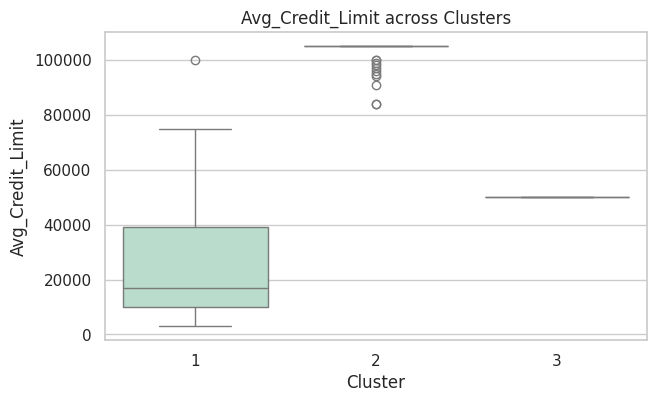

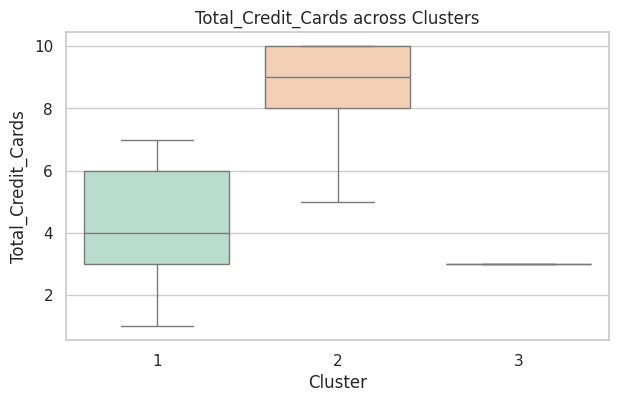

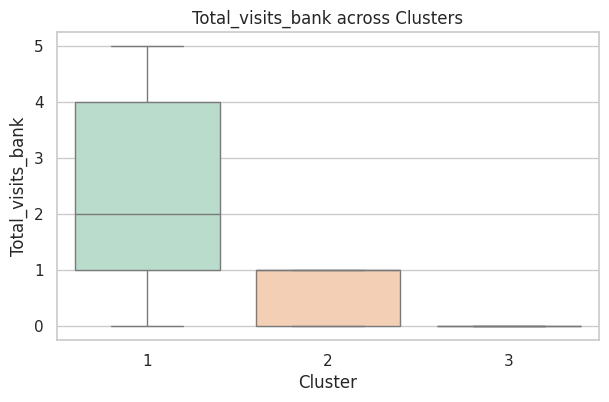

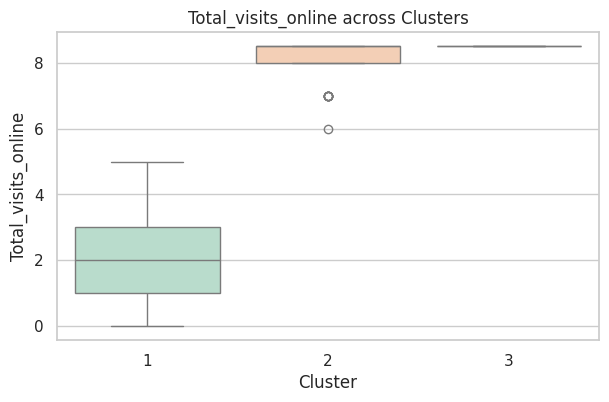

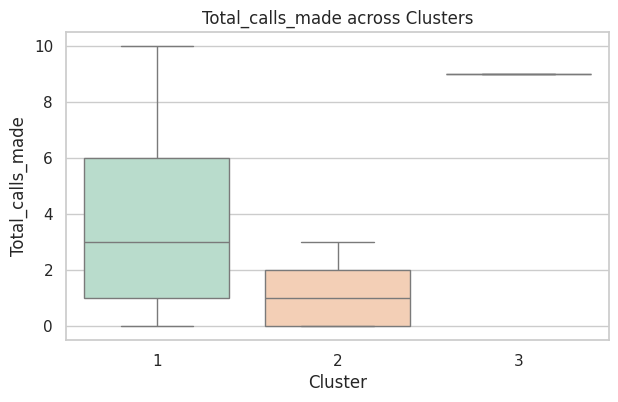

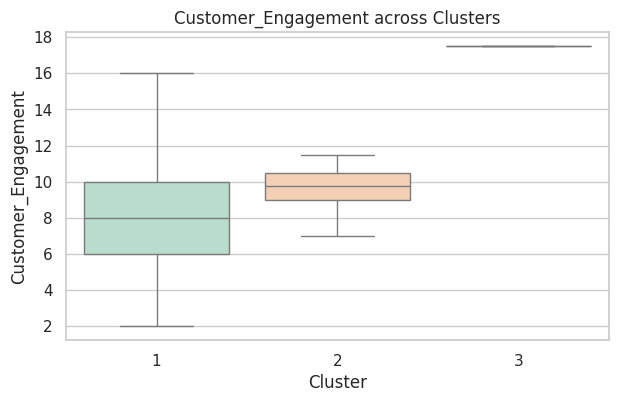

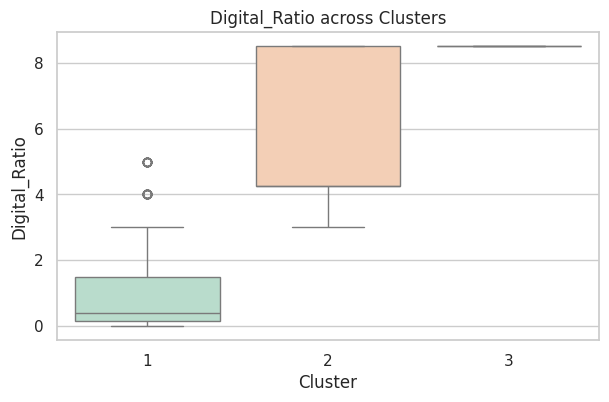

In [243]:
# Boxplot

features = hc_df.columns[:-1]

for col in features:

    plt.figure(figsize=(7,4))

    sns.boxplot(
        x="Cluster",
        y=col,
        data=hc_df,
        palette="Pastel2"
    )

    plt.title(f"{col} across Clusters")

    plt.show()

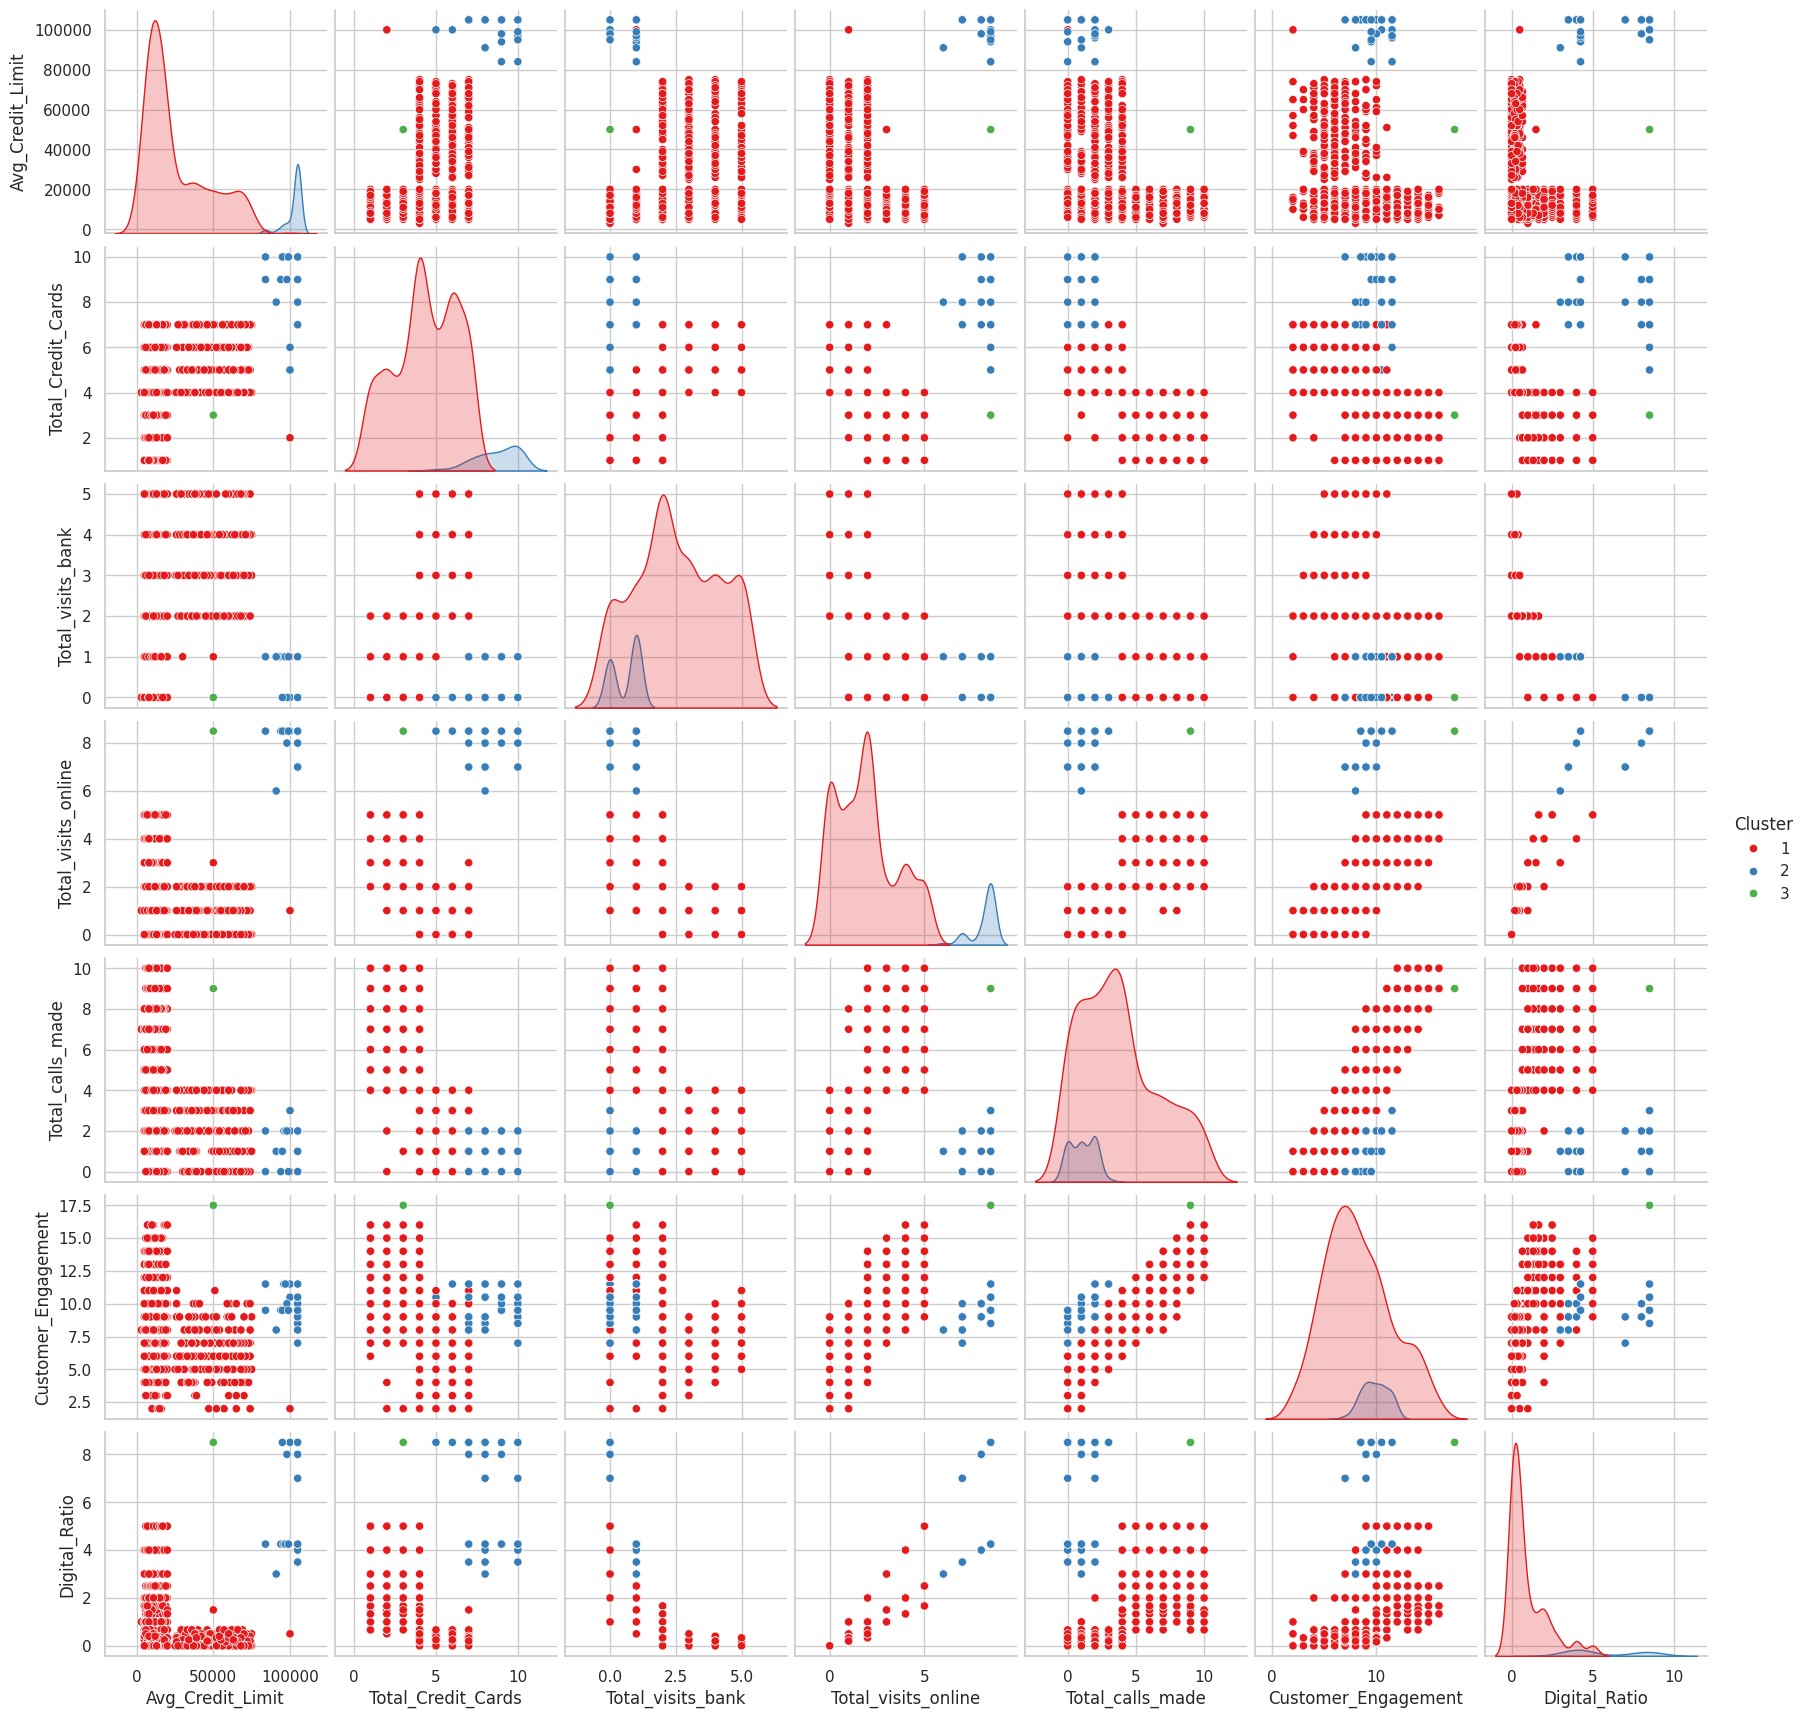

In [244]:
# Pairplot

sns.pairplot(
    hc_df,
    hue="Cluster",
    palette="Set1"
)

plt.show()

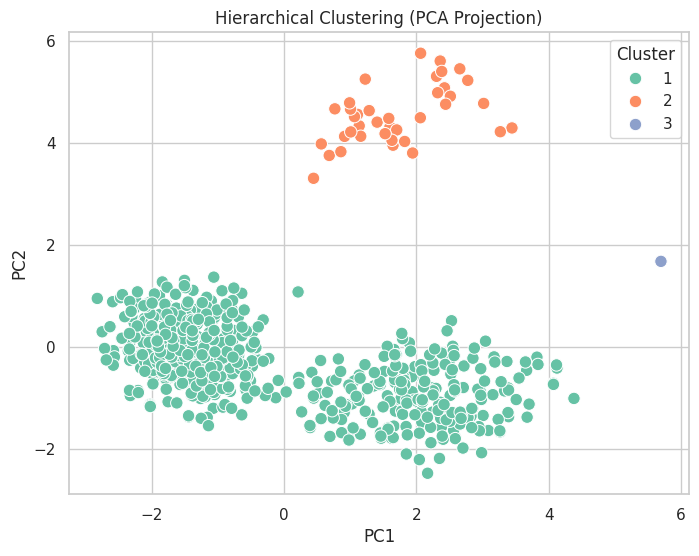

In [245]:
# PCA Visualization

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_df)

plot_df = pd.DataFrame(
    pca_data,
    columns=["PC1","PC2"]
)

plot_df["Cluster"] = hc_clusters

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=80
)

plt.title("Hierarchical Clustering (PCA Projection)")

plt.show()

In [246]:
# Cluster Summary Table

summary = hc_df.groupby("Cluster").agg({
    "Avg_Credit_Limit":"mean",
    "Total_Credit_Cards":"mean",
    "Total_visits_bank":"mean",
    "Total_visits_online":"mean",
    "Total_calls_made":"mean"
})

summary.round(2)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
1,25807.88,4.38,2.56,1.91,3.78
2,102660.00,8.74,0.60,8.18,1.08
3,50000.00,3.00,0.00,8.50,9.00


# **K-means vs Hierarchical Clustering**

In [247]:
# Add Cluster Labels

comparison_df = df.copy()

comparison_df["KMeans"] = clusters

comparison_df["Hierarchical"] = hc_clusters

comparison_df.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio,KMeans,Hierarchical
0,100000.0,2.0,1.0,1.0,0.0,2.0,0.5,2,1
1,50000.0,3.0,0.0,8.5,9.0,17.5,8.5,0,3
2,50000.0,7.0,1.0,3.0,4.0,8.0,1.5,2,1
3,30000.0,5.0,1.0,1.0,4.0,6.0,0.5,2,1
4,100000.0,6.0,0.0,8.5,3.0,11.5,8.5,1,2


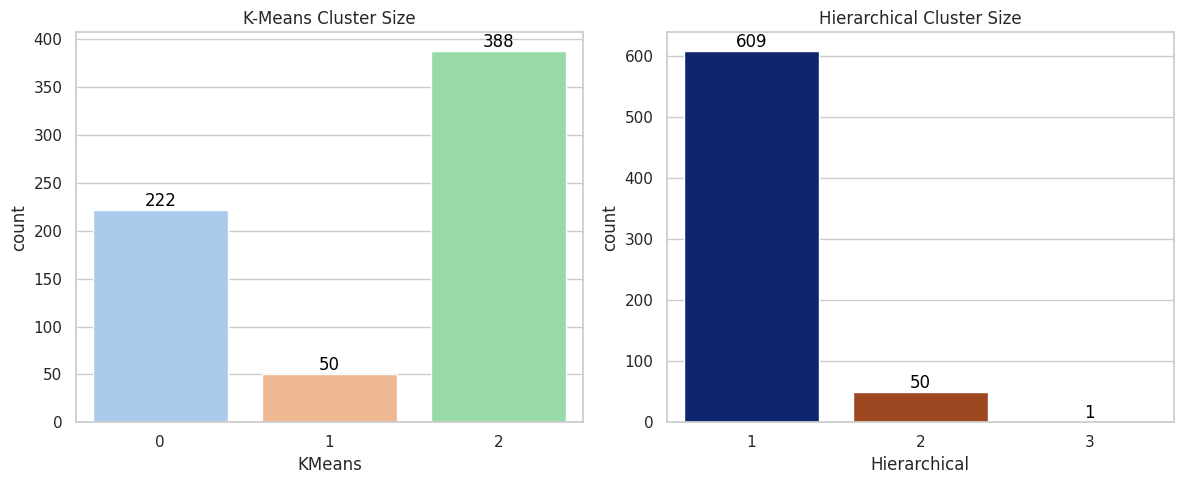

In [248]:
# Compare Cluster Sizes

fig,ax=plt.subplots(1,2,figsize=(12,5))

sns.countplot(
    x="KMeans",
    data=comparison_df,
    palette="pastel",
    ax=ax[0]
)

ax[0].set_title("K-Means Cluster Size")
for container in ax[0].containers:
    ax[0].bar_label(container, fmt='%.0f', label_type='edge', color='black')

sns.countplot(
    x="Hierarchical",
    data=comparison_df,
    palette="dark",
    ax=ax[1]
)

ax[1].set_title("Hierarchical Cluster Size")
for container in ax[1].containers:
    ax[1].bar_label(container, fmt='%.0f', label_type='edge', color='black')

plt.tight_layout()

plt.show()

In [249]:
# Crosstab Comparison

pd.crosstab(
    comparison_df["KMeans"],
    comparison_df["Hierarchical"]
)

Hierarchical,1,2,3
KMeans,,,
0,221,0,1
1,0,50,0
2,388,0,0


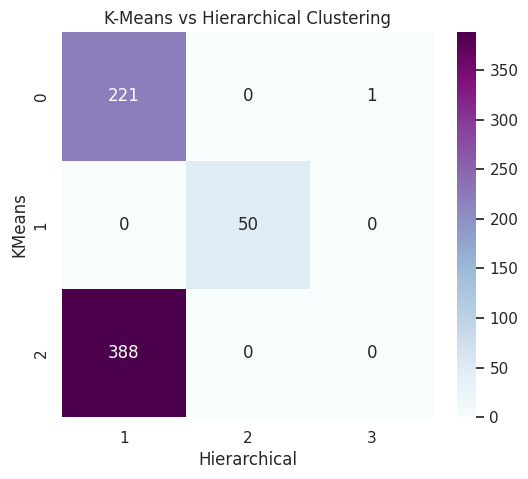

In [250]:
# Heatmap

plt.figure(figsize=(6,5))

sns.heatmap(
    pd.crosstab(
        comparison_df["KMeans"],
        comparison_df["Hierarchical"]
    ),
    annot=True,
    cmap="BuPu",
    fmt="d"
)

plt.title("K-Means vs Hierarchical Clustering")

plt.show()

In [251]:
# Compare Cluster Profiles

print("K-Means Cluster Profile")

display(kmeans_profile)

print("Hierarchical Cluster Profile")

display(hier_profile)

K-Means Cluster Profile


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio
Cluster,,,,,,,
0,12184.684685,2.400901,0.932432,3.565315,6.909910,11.407658,2.234985
1,102660.000000,8.740000,0.600000,8.180000,1.080000,9.860000,5.745000
2,33664.948454,5.505155,3.476804,0.984536,2.002577,6.463918,0.235954


Hierarchical Cluster Profile


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Customer_Engagement,Digital_Ratio
Cluster,,,,,,,
1,25807.881773,4.377668,2.555008,1.912972,3.779967,8.247947,0.951095
2,102660.000000,8.740000,0.600000,8.180000,1.080000,9.860000,5.745000
3,50000.000000,3.000000,0.000000,8.500000,9.000000,17.500000,8.500000


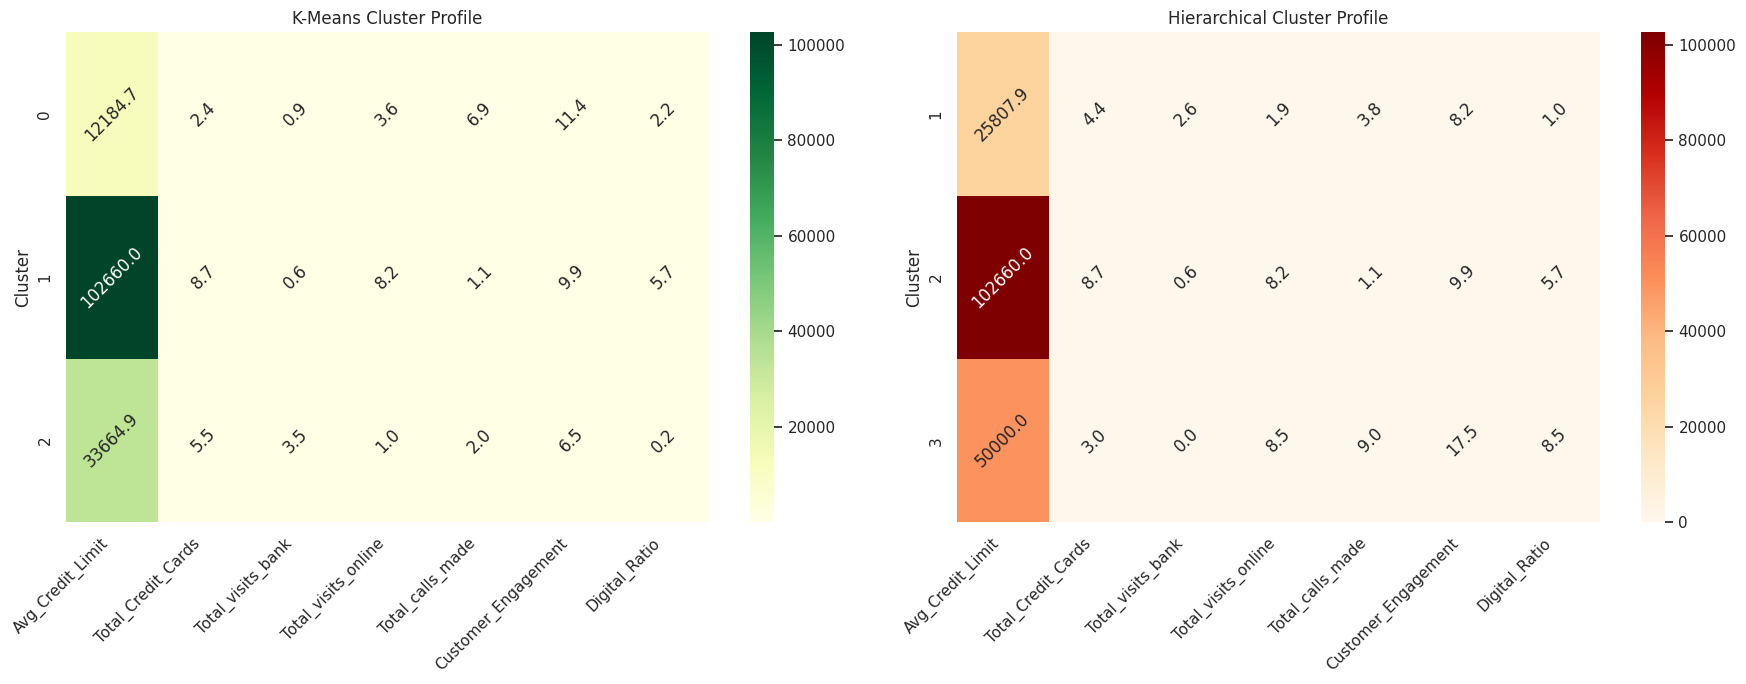

In [252]:
# Heatmaps

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# K-Means Heatmap
ax0_heatmap = sns.heatmap(
    kmeans_profile,
    annot=True,
    cmap="YlGn",
    fmt=".1f",
    ax=axes[0]
)
axes[0].set_title("K-Means Cluster Profile")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
for text in ax0_heatmap.texts:
    text.set_rotation(45)

# Hierarchical Heatmap
ax1_heatmap = sns.heatmap(
    hier_profile,
    annot=True,
    cmap="OrRd",
    fmt=".1f",
    ax=axes[1]
)
axes[1].set_title("Hierarchical Cluster Profile")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
for text in ax1_heatmap.texts:
    text.set_rotation(45)

plt.tight_layout()
plt.show()

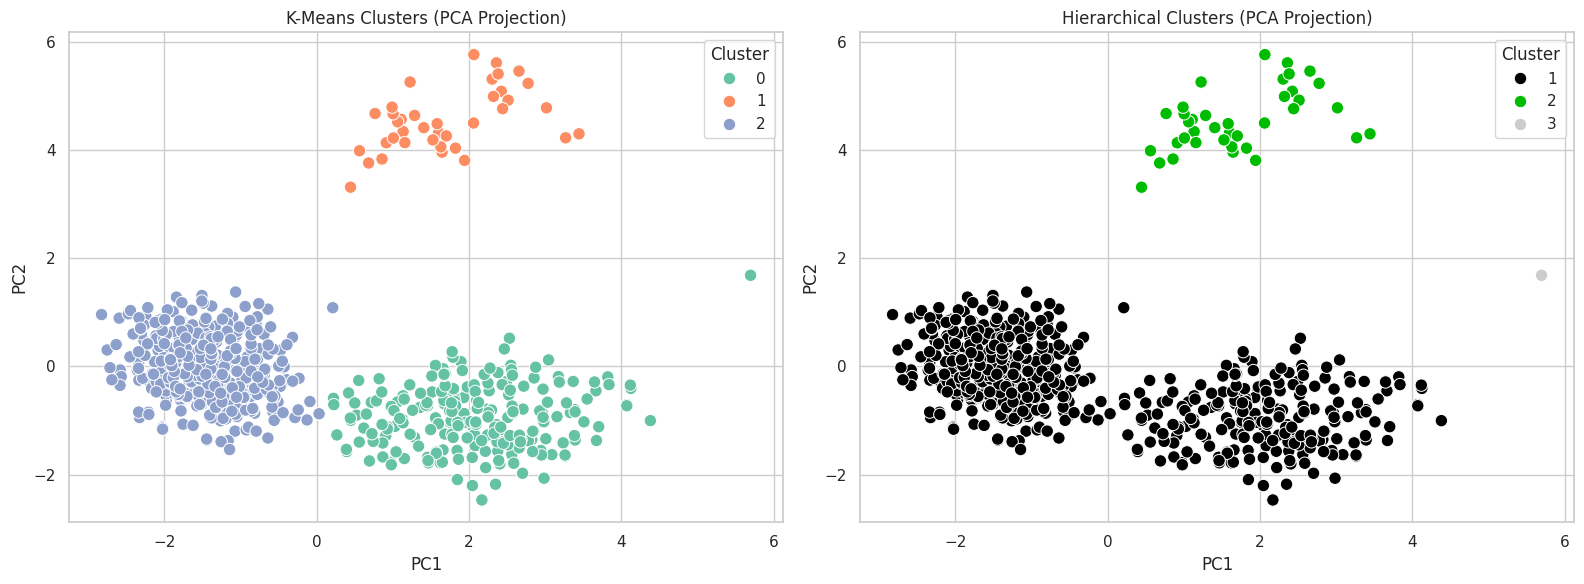

In [253]:
# PCA Comparison
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_df)

plot_df = pd.DataFrame(pca_data, columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means
plot_df["Cluster"] = clusters
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=80,
    ax=axes[0]
)
axes[0].set_title("K-Means Clusters (PCA Projection)")

# Hierarchical
plot_df["Cluster"] = hc_clusters
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="nipy_spectral",
    s=80,
    ax=axes[1]
)
axes[1].set_title("Hierarchical Clusters (PCA Projection)")

plt.tight_layout()
plt.show()

In [254]:
# Silhouette Score Comparison

kmeans_score = silhouette_score(
    scaled_df,
    clusters
)

hier_score = silhouette_score(
    scaled_df,
    hc_clusters
)

print("K-Means Silhouette Score :",round(kmeans_score,3))

print("Hierarchical Silhouette Score :",round(hier_score,3))

K-Means Silhouette Score : 0.508
Hierarchical Silhouette Score : 0.463
